# GLBL 570 · Week 8 — Spatial Analysis for Global Studies: Companion Notebook

Week 7 asked **"what is where?"** This week the map becomes an **instrument**: combine layers, measure distance, test whether a pattern is real, and let a model infer the ground from space. Each section follows a chapter of `GLBL570_Week8_Spatial_Analysis_v3.pptx` and writes the figures the deck's `[FIGURE SLOT]` notes name.

| § | Chapter | LO | Deck slides | Figures written to `outputs/` |
|---|---|---|---|---|
| 0 | Setup and the data pack | — | — | — |
| 1 | From mapping to analysis | — | 7–14 | — |
| 2 | Overlay analysis | **1** | 16–18 | `overlay_operations.png` (17) · `overlay_policy_forest_protected.png` (18) |
| 3 | Buffer, distance and proximity | **1** | 20–25 | `distance_to_water_development.png` (21) · `buffer_sensitivity.png` (23) · `proximity_toolbox.png` (24) · `data_preprocessing_dissolve_integrate.png` (25) |
| 4 | Patterns, clusters and hotspots | **2** | 27–34 | `clusters_moran_lisa.png` (27) · `spatial_correlation_two_variables.png` (28) · `hotspots_getis_ord.png` (33) · `point_pattern_nn.png` (34) |
| 5 | Remote sensing and machine learning | **3** | 36–41 | `rs_ndvi_classification.png` (37) · `ml_confusion_matrix.png` (41) |
| 6 | Policy and the politics of categories | **4** | 43–46 | `categories_forest_definitions.png` (43) · `maup_two_aggregations.png` (45) · `ethics_point_vs_aggregated.png` (46) |
| 7 | Discussion and AI engagement | — | 48–49 | — |
| 8 | Lab and deliverable | **5** | 51–52 | memo template, QGIS layers, figure checklist |

**One continuous case.** §§2–4 work in the **Pacific Northwest**: the overlay, distance and preprocessing steps in a six-county focus area around **Mount Hood and the Columbia River Gorge** (forest + protected land + a large river + Portland), and the cluster statistics on all **Oregon, Washington and Idaho** counties, which contain the focus area. The humanitarian buffer/proximity track (§3.2) uses the **Rohingya refugee camps of Cox's Bazar** and UCDP conflict events.

**Every analytical section ends with a line beginning `CANNOT ESTABLISH:`** — what the result does not show. Spatial analysis does not remove analytical choices; it makes them consequential.

Run from the repository root (it needs `lab_data/` and `lab_data_week8/`). CPU only, no internet. Needs `scikit-learn` (§5) in addition to the Week 7 libraries.

In [1]:
import os, warnings
from pathlib import Path

import sys
import pyproj
if pyproj.datadir.get_data_dir().startswith(sys.prefix):         # conda: pyproj and GDAL share one PROJ install
    os.environ.setdefault("PROJ_DATA", pyproj.datadir.get_data_dir())   # tell GDAL where proj.db is
warnings.filterwarnings("ignore", message="Numba not installed")
warnings.filterwarnings("ignore", message="Setting the shape on a NumPy array")   # raised inside rasterio on NumPy >= 2.5

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import rasterio
from rasterio import features
from rasterio.plot import plotting_extent
from scipy import ndimage, sparse, stats
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

LAB, LAB8 = Path("lab_data"), Path("lab_data_week8")
assert LAB.exists() and LAB8.exists(), "Run from the repository root: lab_data/ and lab_data_week8/ must be next to this notebook."
VEC, TAB, RAS = LAB / "vector", LAB / "tables", LAB / "raster"            # Week 7 pack
VEC8, TAB8, RAS8 = LAB8 / "vector", LAB8 / "tables", LAB8 / "raster"      # Week 8 additions
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RNG = np.random.default_rng(570)
ALBERS = 5070                     # NAD83 / Conus Albers: equal-area, metres — all U.S. analysis happens here

PAL = {"blue": "#065A82", "teal": "#1C7293", "green": "#2A7F62", "purple": "#6B5B95", "amber": "#B9791F",
       "terra": "#C05746", "ink": "#25313C", "muted": "#5B6B7A"}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "figure.facecolor": "white", "savefig.bbox": "tight",
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink"], "axes.edgecolor": PAL["muted"],
    "xtick.color": PAL["muted"], "ytick.color": PAL["muted"], "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})


def ramp(*colours):
    return LinearSegmentedColormap.from_list("", colours)


SEQ_BLUE, SEQ_GREEN, SEQ_TERRA = ramp("#EEF4F8", PAL["blue"]), ramp("#F1F7F4", PAL["green"]), ramp("#FBF1EE", PAL["terra"])
DIVERGING = ramp(PAL["blue"], "#F2F2F2", PAL["terra"])
MISSING = {"color": "#D9D9D9", "hatch": "////", "edgecolor": "#9A9A9A", "label": "no data"}
FIGS = {}                         # figure file -> deck slide, filled by save()


def source(fig, text):
    fig.text(0.01, -0.01, "Source: " + text, fontsize=6, color=PAL["muted"], ha="left", va="top")


def save(fig, name, slide, pdf=False):
    fig.savefig(OUT / name, dpi=220, bbox_inches="tight", facecolor="white")
    if pdf:
        fig.savefig(OUT / Path(name).with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    FIGS[name] = slide
    plt.show()


def cannot(text):
    print("CANNOT ESTABLISH:", text)


def polygons_only(gdf):
    # make_valid can return GeometryCollections; keep the polygonal parts, one row per input feature
    g = gdf.copy(); g["geometry"] = g.make_valid(); g["_row"] = np.arange(len(g))
    g = g.explode(index_parts=False); g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])]
    return g.dissolve(by="_row", as_index=False).drop(columns="_row")


print("geopandas", gpd.__version__, "| shapely", shapely.__version__, "| rasterio", rasterio.__version__)

geopandas 1.0.1 | shapely 2.0.2 | rasterio 1.3.8


### 0.1 The data pack
`lab_data/` is the Week 7 pack (unchanged). `lab_data_week8/` adds the layers the syllabus tasks need; `lab_data_week8/README.md` lists source, licence, CRS and pitfalls for each.

In [2]:
HOW = {".shp": "drag & drop (vector)", ".tif": "drag & drop (raster)", ".csv": "Add Delimited Text Layer"}
inv = [{"file": str(p), "MB": round(p.stat().st_size / 1e6, 2), "QGIS": HOW[p.suffix]}
       for p in sorted(LAB8.rglob("*")) if p.suffix in HOW]
inv += [{"file": str(VEC / f), "MB": round((VEC / f).stat().st_size / 1e6, 2), "QGIS": HOW[".shp"]}
        for f in ["us_counties_acs2022.shp", "usgs_earthquakes_2025_m25.shp", "world_countries_ne110m.shp"]]
inv += [{"file": str(RAS / f), "MB": round((RAS / f).stat().st_size / 1e6, 2), "QGIS": HOW[".tif"]}
        for f in ["champaign_sentinel2_2023_10m.tif", "illinois_landcover_nlcd2021_150m.tif"]]
display(pd.DataFrame(inv))

,file,MB,QGIS
0,lab_data_week8/raster/focus_nlcd2021_30m.tif,3.85,drag & drop (raster)
1,lab_data_week8/raster/focus_srtm_90m.tif,3.29,drag & drop (raster)
2,lab_data_week8/raster/nlcd_classes.csv,0.00,Add Delimited Text Layer
3,lab_data_week8/tables/ucdp_ged_2023_near_camps...,0.06,Add Delimited Text Layer
4,lab_data_week8/vector/coxsbazar_camps_2023.shp,0.18,drag & drop (vector)
5,lab_data_week8/vector/focus_counties_pnw.shp,0.01,drag & drop (vector)
6,lab_data_week8/vector/padus41_mthood_gorge.shp,1.46,drag & drop (vector)
7,lab_data/vector/us_counties_acs2022.shp,3.78,drag & drop (vector)
8,lab_data/vector/usgs_earthquakes_2025_m25.shp,0.14,drag & drop (vector)
9,lab_data/vector/world_countries_ne110m.shp,0.18,drag & drop (vector)


---
## 1 · From Mapping to Analysis  (slides 7–14)
Week 7's county map was a **description**: one layer answering *what is where*. Analysis asks what locations mean **together** (slide 7). Slide 11's test for whether an analysis is *spatial*: **when the location changes, does the information content change?** A histogram passes the shuffle test unchanged; the relationship between a place and its neighbours does not.

The neighbour relation is built once here, for the **Pacific Northwest** counties (Oregon, Washington, Idaho), and reused in §4.

Counties without a neighbour (dropped): ['San Juan County']
Pacific Northwest: 118 counties (OR 36, WA 38, ID 44), mean 5.1 neighbours


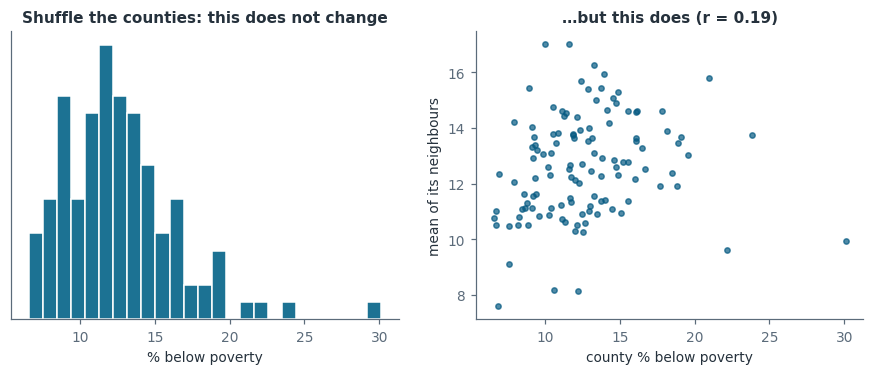

In [3]:
FIELDS = pd.read_csv(VEC / "us_counties_acs2022_field_dictionary.csv")
counties = gpd.read_file(VEC / "us_counties_acs2022.shp").rename(columns=dict(zip(FIELDS.shapefile_field, FIELDS.acs_field)))
pnw = counties[counties.state_abbr.isin(["OR", "WA", "ID"])].to_crs(ALBERS).reset_index(drop=True)

nb = gpd.sjoin(pnw[["geometry"]], pnw[["geometry"]], predicate="intersects")      # queen contiguity
nb = nb[nb.index != nb.index_right]
islands = sorted(set(pnw.index) - set(nb.index))
print("Counties without a neighbour (dropped):", pnw.loc[islands, "county_label"].tolist())
keep = np.setdiff1d(pnw.index, islands)
R = pnw.loc[keep].reset_index(drop=True)
remap = {old: new for new, old in enumerate(keep)}
i, j = nb.index.map(remap), nb.index_right.map(remap)
ok = ~(pd.isna(i) | pd.isna(j))
Wb = sparse.csr_matrix((np.ones(ok.sum()), (np.asarray(i[ok], int), np.asarray(j[ok], int))), shape=(len(R),) * 2)
kdeg = np.asarray(Wb.sum(axis=1)).ravel()
W = sparse.diags(1 / kdeg) @ Wb                                                  # row-standardised
print(f"Pacific Northwest: {len(R)} counties (OR {sum(R.state_abbr=='OR')}, WA {sum(R.state_abbr=='WA')}, "
      f"ID {sum(R.state_abbr=='ID')}), mean {kdeg.mean():.1f} neighbours")

x = R.poverty_pct.values
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.hist(x, bins=25, color=PAL["teal"], edgecolor="white"); a1.set_yticks([])
a1.set_xlabel("% below poverty"); a1.set_title("Shuffle the counties: this does not change")
lag = W @ x
a2.scatter(x, lag, s=12, color=PAL["blue"], alpha=0.7)
a2.set_xlabel("county % below poverty"); a2.set_ylabel("mean of its neighbours")
a2.set_title(f"…but this does (r = {np.corrcoef(x, lag)[0, 1]:.2f})")
plt.show()

---
## 2 · Overlay Analysis  (slides 16–18) · **LO 1**
Overlay is a **join whose key is geography** (slide 16). The operations differ in **which pieces survive** and **whose attributes they carry**:

| Operation | Geometry kept | Attributes |
|---|---|---|
| **Clip** | A ∩ B | A only |
| **Intersect** | A ∩ B | A and B |
| **Erase** | A − B | A only |
| **Union** | everything, cut at every edge | both (nulls where absent) |
| **Identity** | all of A, cut by B | A + B where they coincide |
| **Symmetric difference** | everything except A ∩ B | both |

### 2.1 The focus area and the two layers
Six counties around Mount Hood and the Columbia River Gorge. **Forest** comes from NLCD 2021 (30 m, raw class codes); **protected areas** from **PAD-US 4.1** (USGS Gap Analysis Project). PAD-US records protection by **GAP status**: 1–2 = managed for biodiversity, 3 = multiple use (e.g. most national-forest land), 4 = no known mandate.

In [4]:
focus = gpd.read_file(VEC8 / "focus_counties_pnw.shp").to_crs(ALBERS)
with rasterio.open(RAS8 / "focus_nlcd2021_30m.tif") as src:
    lc, lc_tf, lc_crs, lc_ext = src.read(1), src.transform, src.crs, plotting_extent(src)
    NLCD_CMAP = {k: tuple(c / 255 for c in v) for k, v in src.colormap(1).items()}
assert lc_crs.to_epsg() == ALBERS, lc_crs                      # the raster is on the analysis CRS
NLCD_LABEL = dict(pd.read_csv(RAS8 / "nlcd_classes.csv").values)
land = lc > 0
CELL_KM2 = 30 * 30 / 1e6

pad_raw = gpd.read_file(VEC8 / "padus41_mthood_gorge.shp").to_crs(ALBERS)
print(f"PAD-US: {len(pad_raw):,} features; {(~pad_raw.is_valid).sum()} invalid after reprojection -> repaired")
pad = polygons_only(pad_raw)
pad["GAP"] = pad.GAP_Sts.astype(int)
gap12 = gpd.GeoDataFrame({"zone": ["GAP 1-2"]}, geometry=[pad[pad.GAP <= 2].union_all()], crs=ALBERS)
gap123 = gpd.GeoDataFrame({"zone": ["GAP 1-3"]}, geometry=[pad[pad.GAP <= 3].union_all()], crs=ALBERS)


def vectorize(mask, label):
    shapes = features.shapes(mask.astype("uint8"), mask=mask, transform=lc_tf, connectivity=8)
    geoms = [shapely.geometry.shape(g) for g, v in shapes if v == 1]
    return gpd.GeoDataFrame({"cls": [label] * len(geoms)}, geometry=geoms, crs=ALBERS)


FOREST_CODES = [41, 42, 43]               # deciduous, evergreen, mixed — §6.1 questions this choice
forest = vectorize(np.isin(lc, FOREST_CODES) & land, "forest")
print(f"focus area {focus.area.sum() / 1e6:,.0f} km² | forest {forest.area.sum() / 1e6:,.0f} km² in {len(forest):,} polygons")
print(f"protected (dissolved): GAP 1-2 {gap12.area.sum() / 1e6:,.0f} km² | GAP 1-3 {gap123.area.sum() / 1e6:,.0f} km²")

PAD-US: 3,043 features; 1 invalid after reprojection -> repaired


focus area 19,726 km² | forest 9,860 km² in 24,798 polygons
protected (dissolved): GAP 1-2 2,085 km² | GAP 1-3 9,774 km²


### 2.2 The six operations on two simple shapes (slide 17)

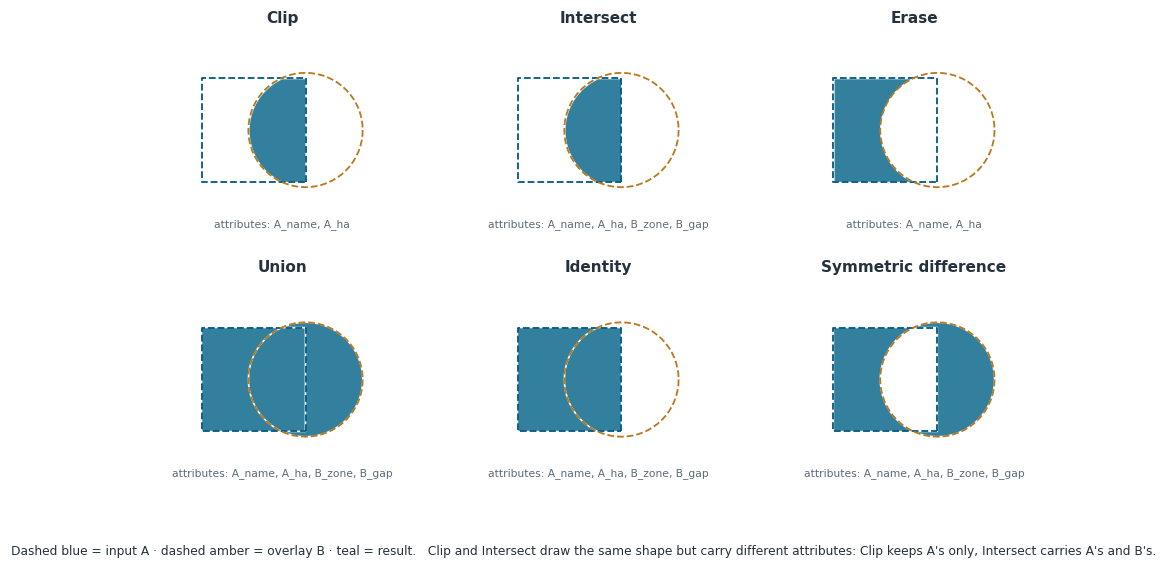

Clip      attribute table: ['A_name', 'A_ha']
Intersect attribute table: ['A_name', 'A_ha', 'B_zone', 'B_gap']


In [5]:
from shapely.geometry import box, Point
A = gpd.GeoDataFrame({"A_name": ["forest stand"], "A_ha": [400]}, geometry=[box(0, 0, 2, 2)], crs=3857)
B = gpd.GeoDataFrame({"B_zone": ["reserve"], "B_gap": [1]}, geometry=[Point(2, 1).buffer(1.1)], crs=3857)
OPS = {"Clip": gpd.clip(A, B), "Intersect": gpd.overlay(A, B, how="intersection"),
       "Erase": gpd.overlay(A, B, how="difference"), "Union": gpd.overlay(A, B, how="union"),
       "Identity": gpd.overlay(A, B, how="identity"), "Symmetric difference": gpd.overlay(A, B, how="symmetric_difference")}
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.4)); axes = axes.ravel()
for ax, (name, g) in zip(axes, OPS.items()):
    A.boundary.plot(ax=ax, color=PAL["blue"], lw=1.2, ls="--"); B.boundary.plot(ax=ax, color=PAL["amber"], lw=1.2, ls="--")
    g.plot(ax=ax, color=PAL["teal"], edgecolor="white", lw=1.0, alpha=0.9)
    attrs = ", ".join(c for c in g.columns if c != "geometry")
    ax.set_title(name); ax.text(1.55, -0.85, f"attributes: {attrs}", ha="center", fontsize=7, color=PAL["muted"])
    ax.set_xlim(-0.3, 3.4); ax.set_ylim(-1.1, 2.9); ax.set_aspect("equal"); ax.set_axis_off()
fig.text(0.5, 0.0, "Dashed blue = input A · dashed amber = overlay B · teal = result.   "
         "Clip and Intersect draw the same shape but carry different attributes: Clip keeps A's only, Intersect carries A's and B's.",
         ha="center", fontsize=8, color=PAL["ink"])
save(fig, "overlay_operations.png", 17, pdf=True)
for k in ["Clip", "Intersect"]:
    print(f"{k:9s} attribute table:", [c for c in OPS[k].columns if c != "geometry"])

### 2.3 The same operations on the real layers
Input A = the six counties; overlay B = PAD-US units with GAP status 1–2. Watch the row count and the attribute list.

In [6]:
Acty = focus[["NAME", "STUSPS", "geometry"]]
Bpa = pad[pad.GAP <= 2][["Unit_Nm", "GAP", "Mang_Name", "geometry"]]
real = {"clip": gpd.clip(Acty, Bpa), "intersect": gpd.overlay(Acty, Bpa, how="intersection", keep_geom_type=True),
        "erase": gpd.overlay(Acty, Bpa, how="difference", keep_geom_type=True),
        "union": gpd.overlay(Acty, Bpa, how="union", keep_geom_type=True),
        "identity": gpd.overlay(Acty, Bpa, how="identity", keep_geom_type=True),
        "symmetric difference": gpd.overlay(Acty, Bpa, how="symmetric_difference", keep_geom_type=True)}
display(pd.DataFrame([{"operation": k, "rows out": len(g), "km²": round(g.area.sum() / 1e6),
                       "attributes": ", ".join(c for c in g.columns if c != "geometry")} for k, g in real.items()]).set_index("operation"))
print(f"inputs: {len(Acty)} counties, {len(Bpa)} protected units (GAP 1-2)")

,rows out,km²,attributes
operation,,,
clip,6,2085,"NAME, STUSPS"
intersect,382,2474,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"
erase,6,17642,"NAME, STUSPS"
union,409,20116,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"
identity,388,20116,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"
symmetric difference,27,17642,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"


inputs: 6 counties, 360 protected units (GAP 1-2)


### 2.4 Forest × protected areas: the conservation gap (slide 18)
**Intersect** gives the protected forest, **erase** gives the gap. Both are reported for two definitions of "protected" — strict (GAP 1–2) and including multiple-use land (GAP 1–3) — because the answer depends on that choice (§6).

forest 9,860 km² | strictly protected (GAP 1-2) 1,377 km² = 14.0% | gap 8,483 km² | incl. multiple use (GAP 1-3) 7,232 km² = 73.3%


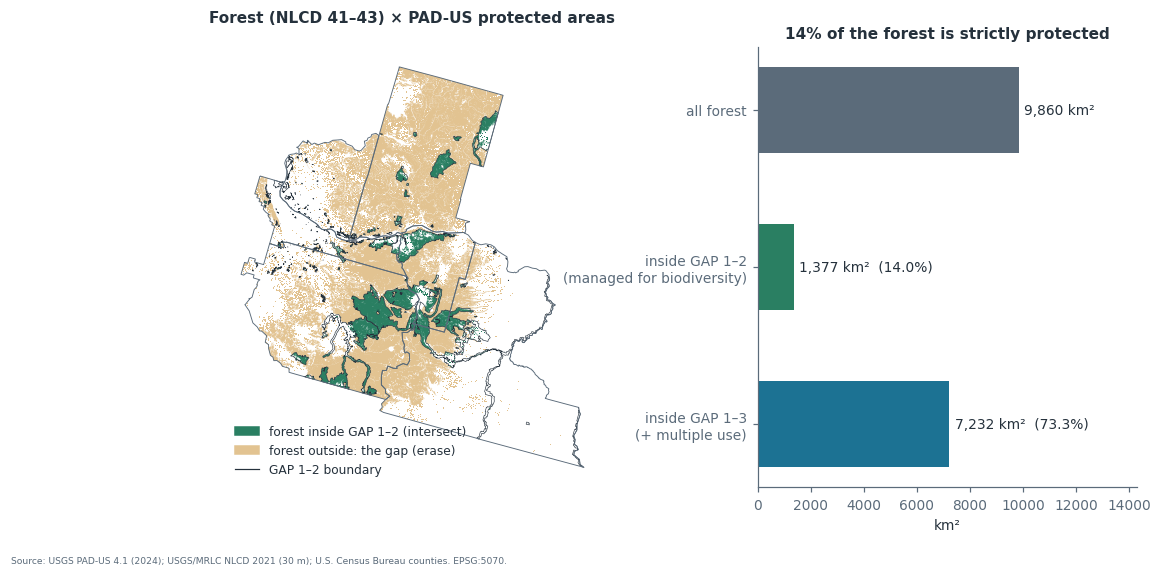

,forest km²,strictly protected km²,% protected
NAME,,,
Skamania,3516.0,209.0,5.9
Clackamas,2944.0,666.0,22.6
Wasco,1308.0,145.0,11.1
Hood River,942.0,293.0,31.1
Clark,667.0,4.0,0.6
Multnomah,483.0,60.0,12.4


CANNOT ESTABLISH: whether protected forest is in better condition than the gap. GAP status records management intent, not enforcement or outcomes; NLCD 2021 is one 30 m snapshot; PAD-US geometry was generalised to ~30 m.


In [7]:
inside12 = gpd.overlay(forest, gap12, how="intersection", keep_geom_type=True)      # forest INSIDE strict protection
gap_forest = gpd.overlay(forest, gap12, how="difference", keep_geom_type=True)    # forest OUTSIDE it: the gap
inside123 = gpd.overlay(forest, gap123, how="intersection", keep_geom_type=True)
F_km2, P12, P123 = forest.area.sum() / 1e6, inside12.area.sum() / 1e6, inside123.area.sum() / 1e6
pct12, pct123 = 100 * P12 / F_km2, 100 * P123 / F_km2
print(f"forest {F_km2:,.0f} km² | strictly protected (GAP 1-2) {P12:,.0f} km² = {pct12:.1f}% | "
      f"gap {gap_forest.area.sum() / 1e6:,.0f} km² | incl. multiple use (GAP 1-3) {P123:,.0f} km² = {pct123:.1f}%")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
gap_forest.plot(ax=a1, color="#E2C391", lw=0)
inside12.plot(ax=a1, color=PAL["green"], lw=0)
gap12.boundary.plot(ax=a1, color=PAL["ink"], lw=0.4)
focus.boundary.plot(ax=a1, color=PAL["muted"], lw=0.6)
a1.legend([Patch(color=PAL["green"]), Patch(color="#E2C391"), Line2D([], [], color=PAL["ink"], lw=0.8)],
          ["forest inside GAP 1–2 (intersect)", "forest outside: the gap (erase)", "GAP 1–2 boundary"], loc="lower left", fontsize=8)
a1.set_title("Forest (NLCD 41–43) × PAD-US protected areas"); a1.set_axis_off()
bars = [("all forest", F_km2, PAL["muted"]), ("inside GAP 1–2\n(managed for biodiversity)", P12, PAL["green"]),
        ("inside GAP 1–3\n(+ multiple use)", P123, PAL["teal"])]
a2.barh([b[0] for b in bars], [b[1] for b in bars], color=[b[2] for b in bars], height=0.55)
for k, (lab, v, _) in enumerate(bars):
    a2.text(v + F_km2 * 0.02, k, f"{v:,.0f} km²" + ("" if k == 0 else f"  ({100 * v / F_km2:.1f}%)"), va="center", fontsize=9)
a2.invert_yaxis(); a2.set_xlim(0, F_km2 * 1.45); a2.set_xlabel("km²")
a2.set_title(f"{pct12:.0f}% of the forest is strictly protected")
source(fig, "USGS PAD-US 4.1 (2024); USGS/MRLC NLCD 2021 (30 m); U.S. Census Bureau counties. EPSG:5070.")
save(fig, "overlay_policy_forest_protected.png", 18)

per = (gpd.overlay(inside12, focus[["NAME", "geometry"]], how="intersection", keep_geom_type=True)
       .assign(km2=lambda d: d.area / 1e6).groupby("NAME").km2.sum())
allf = (gpd.overlay(forest, focus[["NAME", "geometry"]], how="intersection", keep_geom_type=True)
        .assign(km2=lambda d: d.area / 1e6).groupby("NAME").km2.sum())
t = pd.DataFrame({"forest km²": allf.round(0), "strictly protected km²": per.reindex(allf.index).fillna(0).round(0)})
t["% protected"] = (100 * t.iloc[:, 1] / t.iloc[:, 0]).round(1)
display(t.sort_values("forest km²", ascending=False))
cannot("whether protected forest is in better condition than the gap. GAP status records management intent, not "
       "enforcement or outcomes; NLCD 2021 is one 30 m snapshot; PAD-US geometry was generalised to ~30 m.")

---
## 3 · Buffer, Distance and Proximity  (slides 20–25) · **LO 1**
A **buffer** turns distance into yes/no; a **distance surface** keeps it continuous. *The buffer distance is an assumption* (slide 20): state it and show how far the answer moves when it changes. Distances are measured in metre-based CRSs (EPSG:5070 here, UTM 46N in Cox's Bazar).

### 3.1 Distance to water and development (slide 21)
Every 30 m cell gets its exact Euclidean distance to the nearest open-water cell (NLCD class 11).

,land km²,% developed
distance to water (m),,
0–100,522,7.7
100–250,448,17.7
250–500,880,15.4
0.5–1k,1926,13.4
1–2k,3627,11.1
2–5k,7277,8.0
>5k,5047,3.2


median distance to water: developed cells 1,758 m vs all land 2,806 m


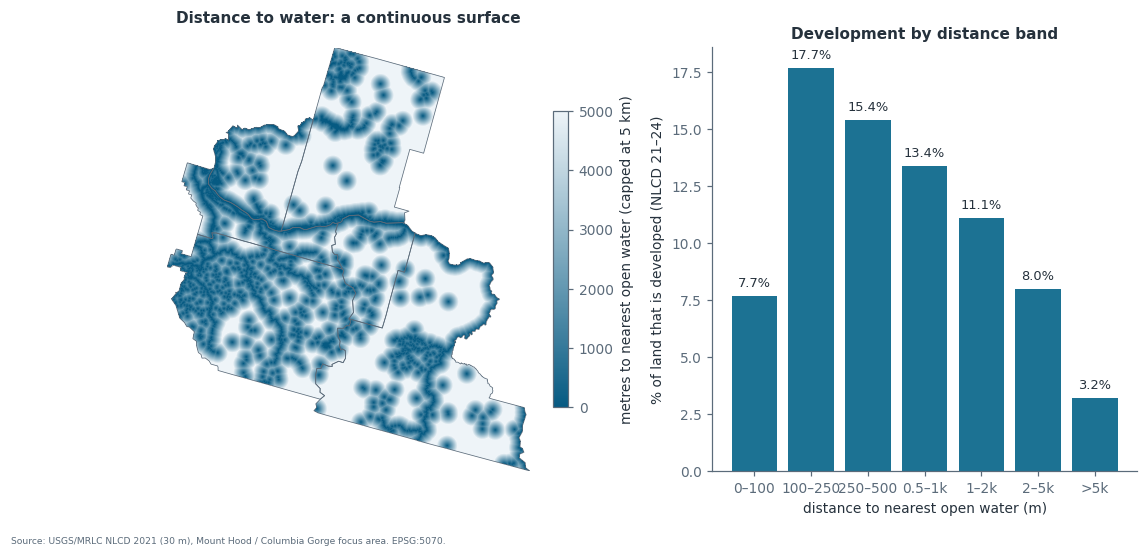

CANNOT ESTABLISH: that water causes development. Portland grew on the Columbia for transport; terrain, roads and zoning co-vary with distance to water. Straight-line distance also ignores that a river is often a barrier.


In [8]:
dist = ndimage.distance_transform_edt(lc != 11, sampling=30.0)
dist = np.where(land, dist, np.nan)
developed = np.isin(lc, [21, 22, 23, 24]) & land
edges = np.array([0, 100, 250, 500, 1000, 2000, 5000, np.inf])
labels = ["0–100", "100–250", "250–500", "0.5–1k", "1–2k", "2–5k", ">5k"]
band = np.digitize(np.nan_to_num(dist, nan=-1), edges) - 1
prox = pd.DataFrame([{"distance to water (m)": lab, "land km²": round((land & (band == b)).sum() * CELL_KM2),
                      "% developed": 100 * (developed & (band == b)).sum() / max((land & (band == b)).sum(), 1)}
                     for b, lab in enumerate(labels)]).set_index("distance to water (m)")
display(prox.round(1))
print(f"median distance to water: developed cells {np.nanmedian(dist[developed]):,.0f} m vs all land {np.nanmedian(dist[land]):,.0f} m")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={"width_ratios": [1.1, 1]})
im = a1.imshow(np.clip(dist, 0, 5000), extent=lc_ext, cmap=SEQ_BLUE.reversed(), interpolation="nearest")
focus.boundary.plot(ax=a1, color=PAL["muted"], lw=0.5)
fig.colorbar(im, ax=a1, shrink=0.7, label="metres to nearest open water (capped at 5 km)")
a1.set_title("Distance to water: a continuous surface"); a1.set_axis_off()
a2.bar(prox.index, prox["% developed"], color=PAL["teal"])
for k, v in enumerate(prox["% developed"]):
    a2.text(k, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8.5)
a2.set_ylabel("% of land that is developed (NLCD 21–24)"); a2.set_xlabel("distance to nearest open water (m)")
a2.set_title("Development by distance band")
source(fig, "USGS/MRLC NLCD 2021 (30 m), Mount Hood / Columbia Gorge focus area. EPSG:5070.")
save(fig, "distance_to_water_development.png", 21)
cannot("that water causes development. Portland grew on the Columbia for transport; terrain, roads and zoning "
       "co-vary with distance to water. Straight-line distance also ignores that a river is often a barrier.")

### 3.2 Humanitarian track: refugee camps and conflict events (slides 20, 23)
*"Which refugee camps fall within X km of conflict zones?"* — the syllabus task, on real data: the 33 camp outlines of the **Rohingya camps in Cox's Bazar** (ISCG, CC0) and **UCDP GED 2023** events within 300 km. Camps are kept as **whole-camp polygons**: no blocks, no shelters, nothing that locates households.

In [9]:
camps = gpd.read_file(VEC8 / "coxsbazar_camps_2023.shp")                     # EPSG:32646 (UTM 46N, metres)
ev = pd.read_csv(TAB8 / "ucdp_ged_2023_near_camps.csv")
evp = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev.longitude, ev.latitude), crs=4326).to_crs(camps.crs)
print(f"{len(camps)} camps ({camps.AreaSqKM.sum():.1f} km²) | {len(evp)} UCDP 2023 events within 300 km "
      f"({evp.country.value_counts().to_dict()})")

D = np.array([evp.distance(g).values for g in camps.geometry]) / 1000          # km: camps x events
camps["nearest_km"] = D.min(axis=1)
camps["third_km"] = np.sort(D, axis=1)[:, 2]                                   # 3rd-nearest: less sensitive to one event
RADII = [1, 2, 5, 10, 25, 50, 100]
share1 = [100 * (D <= r).any(axis=1).mean() for r in RADII]
share3 = [100 * ((D <= r).sum(axis=1) >= 3).mean() for r in RADII]
display(pd.DataFrame({"radius km": RADII, "% camps with ≥1 event within": np.round(share1, 0),
                      "% camps with ≥3 events within": np.round(share3, 0)}).set_index("radius km").T)
print(f"median distance camp -> nearest event {camps.nearest_km.median():.1f} km, -> 3rd nearest {camps.third_km.median():.1f} km")
precise = (evp.where_prec <= 2).values                                   # UCDP: 1 = exact, 2 = within ~25 km
share1_precise = [100 * (D[:, precise] <= r).any(axis=1).mean() for r in RADII]
print(f"location precision of the {len(evp)} events: {evp.where_prec.value_counts().sort_index().to_dict()}")
print("precise events only (where_prec <= 2):", [f"{v:.0f}%" for v in share1_precise],
      "-> same as all events" if np.allclose(share1, share1_precise) else "-> differs: report both")

33 camps (23.6 km²) | 410 UCDP 2023 events within 300 km ({'Myanmar (Burma)': 399, 'Bangladesh': 10, 'India': 1})


radius km,1,2,5,10,25,50,100
% camps with ≥1 event within,64.0,79.0,97.0,100.0,100.0,100.0,100.0
% camps with ≥3 events within,27.0,45.0,76.0,85.0,100.0,100.0,100.0


median distance camp -> nearest event 0.8 km, -> 3rd nearest 2.4 km
location precision of the 410 events: {1: 114, 2: 57, 3: 3, 4: 3, 5: 233}
precise events only (where_prec <= 2): ['64%', '79%', '97%', '100%', '100%', '100%', '100%'] -> same as all events


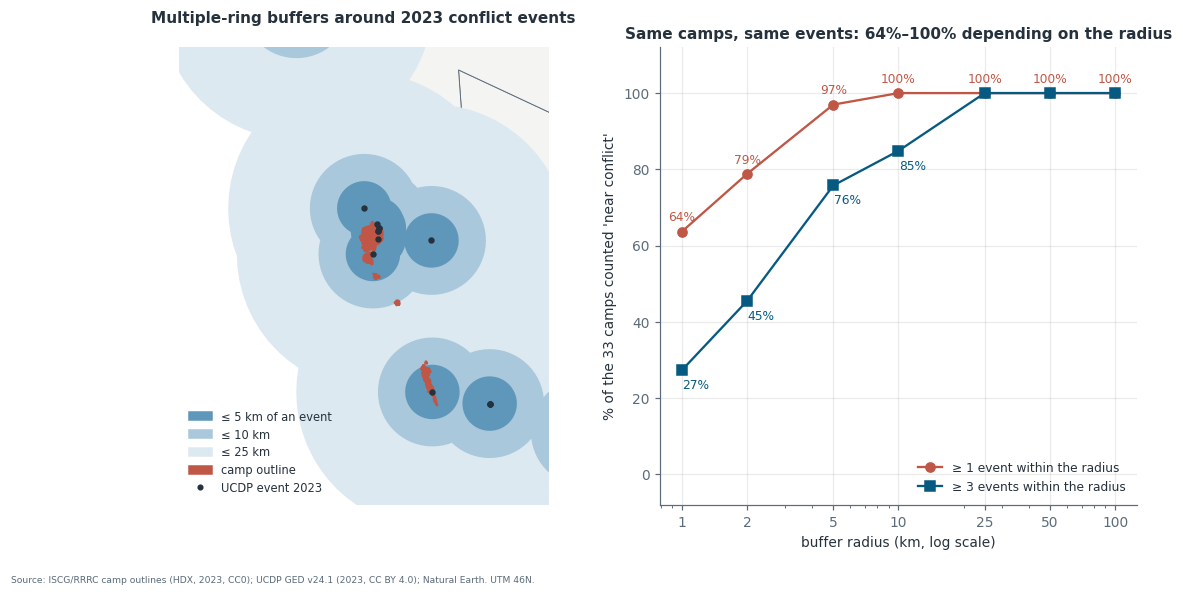

In [10]:
world = gpd.read_file(VEC / "world_countries_ne110m.shp")
cu = camps.union_all().centroid
view = (cu.x - 38_000, cu.y - 42_000, cu.x + 30_000, cu.y + 42_000)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
world[world.NAME.isin(["Bangladesh", "Myanmar", "India"])].to_crs(camps.crs).plot(ax=a1, color="#F4F4F2", edgecolor=PAL["muted"], lw=0.6)
prev = None
for r, c in zip([25, 10, 5], ["#DCE9F1", "#A9C8DB", "#5E97B9"]):
    zone = evp.buffer(r * 1000).union_all()
    gpd.GeoSeries([zone], crs=camps.crs).plot(ax=a1, color=c, lw=0)
camps.plot(ax=a1, color=PAL["terra"], edgecolor=PAL["terra"], lw=1.2)
evp.plot(ax=a1, color=PAL["ink"], markersize=10)
a1.set_xlim(view[0], view[2]); a1.set_ylim(view[1], view[3]); a1.set_axis_off()
a1.legend([Patch(color="#5E97B9"), Patch(color="#A9C8DB"), Patch(color="#DCE9F1"), Patch(color=PAL["terra"]),
           Line2D([], [], ls="", marker="o", color=PAL["ink"], ms=3)],
          ["≤ 5 km of an event", "≤ 10 km", "≤ 25 km", "camp outline", "UCDP event 2023"], loc="lower left", fontsize=7.5)
a1.set_title("Multiple-ring buffers around 2023 conflict events")
a2.plot(RADII, share1, "o-", color=PAL["terra"], label="≥ 1 event within the radius")
a2.plot(RADII, share3, "s-", color=PAL["blue"], label="≥ 3 events within the radius")
for r, v1, v3 in zip(RADII, share1, share3):
    a2.annotate(f"{v1:.0f}%", (r, v1), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=PAL["terra"])
    if abs(v1 - v3) > 4:                                       # one label when the two lines coincide
        a2.annotate(f"{v3:.0f}%", (r, v3), xytext=(9, -12), textcoords="offset points", ha="center", fontsize=8, color=PAL["blue"])
a2.set_xscale("log"); a2.set_xticks(RADII, [str(r) for r in RADII]); a2.set_ylim(-8, 112)
a2.set_xlabel("buffer radius (km, log scale)"); a2.set_ylabel("% of the 33 camps counted 'near conflict'")
a2.legend(loc="lower right", fontsize=8); a2.grid(alpha=0.25)
a2.set_title(f"Same camps, same events: {min(share1):.0f}%–{max(share1):.0f}% depending on the radius")
source(fig, "ISCG/RRRC camp outlines (HDX, 2023, CC0); UCDP GED v24.1 (2023, CC BY 4.0); Natural Earth. UTM 46N.")
save(fig, "buffer_sensitivity.png", 23)

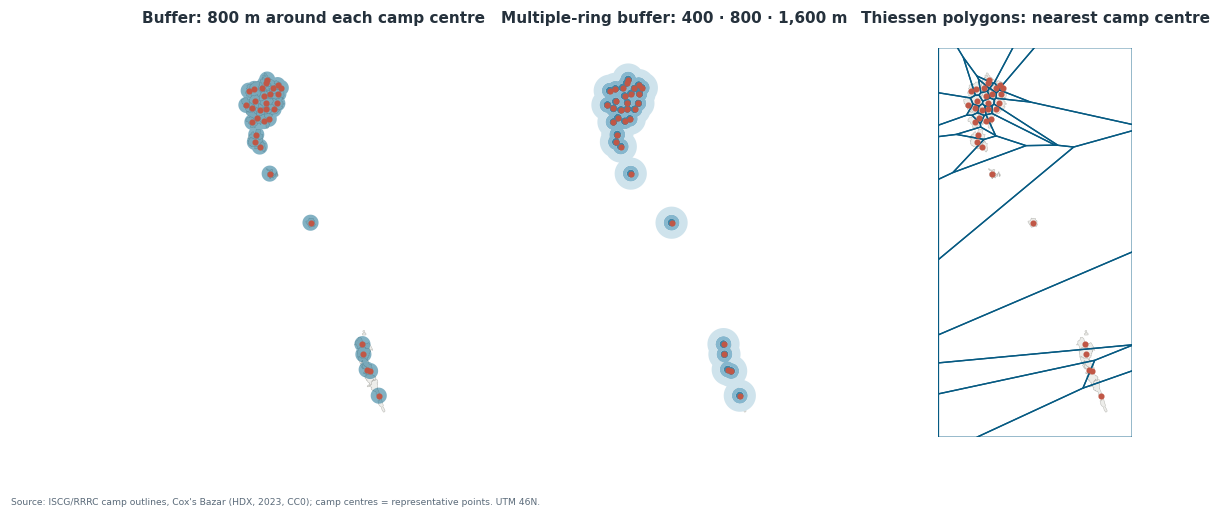

CANNOT ESTABLISH: that a camp near an event is at higher risk. UCDP geocodes events at different precisions (where_prec), Euclidean buffers ignore the border, the Naf river and roads, and 2023 is one year. Thiessen polygons assume people use the nearest point, which camp boundaries contradict.


In [11]:
from shapely.geometry import MultiPoint
from shapely.ops import voronoi_diagram
cp = camps.representative_point()
frame = camps.union_all().buffer(2500).envelope
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax in axes:
    camps.plot(ax=ax, color="#EDEDEA", edgecolor="#B5B5B0", lw=0.3)
gpd.GeoSeries([cp.buffer(800).union_all()], crs=camps.crs).plot(ax=axes[0], color=PAL["teal"], alpha=0.55, lw=0)
axes[0].set_title("Buffer: 800 m around each camp centre")
prev = None
for d, c in zip([400, 800, 1600], ["#3D86A8", "#86B7CE", "#CFE3EC"]):
    cur = cp.buffer(d).union_all()
    gpd.GeoSeries([cur if prev is None else cur.difference(prev)], crs=camps.crs).plot(ax=axes[1], color=c, lw=0)
    prev = cur
axes[1].set_title("Multiple-ring buffer: 400 · 800 · 1,600 m")
vor = gpd.GeoSeries([g.intersection(frame) for g in voronoi_diagram(MultiPoint(list(cp)), envelope=frame).geoms], crs=camps.crs)
vor.boundary.plot(ax=axes[2], color=PAL["blue"], lw=0.9)
axes[2].set_title("Thiessen polygons: nearest camp centre")
x0, y0, x1, y1 = frame.bounds
for ax in axes:
    cp.plot(ax=ax, color=PAL["terra"], markersize=9, zorder=5)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal"); ax.set_axis_off()
source(fig, "ISCG/RRRC camp outlines, Cox's Bazar (HDX, 2023, CC0); camp centres = representative points. UTM 46N.")
save(fig, "proximity_toolbox.png", 24, pdf=True)
cannot("that a camp near an event is at higher risk. UCDP geocodes events at different precisions (where_prec), "
       "Euclidean buffers ignore the border, the Naf river and roads, and 2023 is one year. Thiessen polygons "
       "assume people use the nearest point, which camp boundaries contradict.")

### 3.3 Data preprocessing: dissolve and integrate (slide 25)
**Dissolve** merges features that share a value. PAD-US records overlap (a wilderness inside a national forest inside a scenic area), so summing the raw records double-counts land. **Integrate** makes vertices within a tolerance coincide, removing slivers between neighbours — here between PAD-US *fee* parcels whose shared edges were generalised independently.

dissolve: 3,043 features summing to 15,665 km² -> by GAP status 4 features, 12,352 km² (overlaps between GAP classes remain) -> dissolve all: footprint 9,977 km²; summing raw records overstates protected land by 57%
integrate (30 m): fee parcels 2,434 -> 2,230; small overlaps 540 -> 206; small gaps 483 -> 250


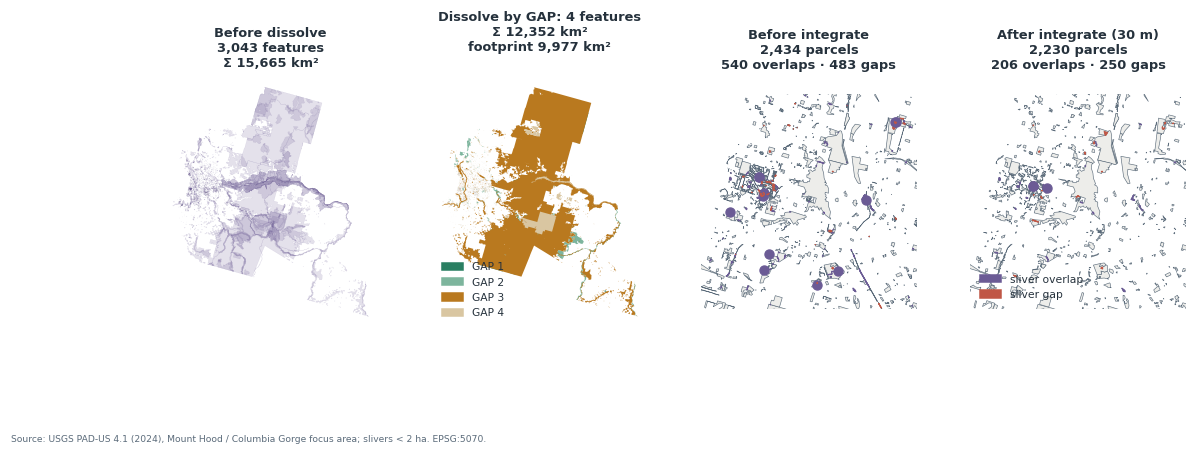

Integrate also deleted 204 parcels smaller than the 30 m tolerance — the tolerance is a choice too.


In [12]:
raw_sum = pad.area.sum() / 1e6
diss = pad.dissolve(by="GAP", as_index=False)
diss_km2 = diss.area.sum() / 1e6
footprint_km2 = pad.union_all().area / 1e6                     # dissolve everything: the true footprint
fee = pad[pad.Category == "Fee"].reset_index(drop=True)


def slivers(gdf, small=20_000):
    pr = gpd.sjoin(gdf[["geometry"]], gdf[["geometry"]], predicate="intersects")
    pr = pr[pr.index < pr.index_right]
    inter = [gdf.geometry[a].intersection(gdf.geometry[b]) for a, b in zip(pr.index, pr.index_right)]
    over = [g for g in inter if 1 < g.area < small]
    u = gdf.union_all()
    holes = [shapely.Polygon(r) for p in getattr(u, "geoms", [u]) for r in p.interiors]
    gaps = [h for h in holes if h.area < small]
    return over, gaps


TOL = 30                                                       # metres = the generalisation tolerance of the data
fee_int = fee.set_geometry(shapely.set_precision(fee.geometry.values, grid_size=TOL))
fee_int = fee_int[~fee_int.is_empty].reset_index(drop=True)
ov0, gp0 = slivers(fee); ov1, gp1 = slivers(fee_int)
print(f"dissolve: {len(pad):,} features summing to {raw_sum:,.0f} km² -> by GAP status {len(diss)} features, {diss_km2:,.0f} km² "
      f"(overlaps between GAP classes remain) -> dissolve all: footprint {footprint_km2:,.0f} km²; "
      f"summing raw records overstates protected land by {100 * (raw_sum / footprint_km2 - 1):.0f}%")
print(f"integrate ({TOL} m): fee parcels {len(fee):,} -> {len(fee_int):,}; small overlaps {len(ov0)} -> {len(ov1)}; "
      f"small gaps {len(gp0)} -> {len(gp1)}")

centres = np.array([[g.centroid.x, g.centroid.y] for g in ov0 + gp0])
dens = cKDTree(centres).query_ball_point(centres, r=6000, return_length=True)
cx, cy = centres[dens.argmax()]
win = (cx - 6000, cy - 6000, cx + 6000, cy + 6000)
GAPC = {1: PAL["green"], 2: "#7DB59D", 3: PAL["amber"], 4: "#D9C6A1"}
fig, axes = plt.subplots(1, 4, figsize=(12, 4.2), gridspec_kw={"wspace": 0.25})
pad.plot(ax=axes[0], color=PAL["purple"], alpha=0.18, edgecolor=PAL["purple"], lw=0.2)
axes[0].set_title(f"Before dissolve\n{len(pad):,} features\nΣ {raw_sum:,.0f} km²", fontsize=8.5)
diss.plot(ax=axes[1], color=[GAPC[g] for g in diss.GAP], lw=0)
axes[1].legend([Patch(color=GAPC[g]) for g in diss.GAP], [f"GAP {g}" for g in diss.GAP], loc="lower left", fontsize=7)
axes[1].set_title(f"Dissolve by GAP: {len(diss)} features\nΣ {diss_km2:,.0f} km²\nfootprint {footprint_km2:,.0f} km²", fontsize=8.5)
for ax, data, ov, gp, ttl in [(axes[2], fee, ov0, gp0, "Before integrate"), (axes[3], fee_int, ov1, gp1, f"After integrate ({TOL} m)")]:
    data.cx[win[0]:win[2], win[1]:win[3]].plot(ax=ax, color="#EDEDEA", edgecolor=PAL["muted"], lw=0.4)
    for gs, col in [(ov, PAL["purple"]), (gp, PAL["terra"])]:
        if gs:
            gpd.GeoSeries(gs, crs=ALBERS).cx[win[0]:win[2], win[1]:win[3]].plot(ax=ax, color=col, lw=0.8, edgecolor=col)
    ax.set_xlim(win[0], win[2]); ax.set_ylim(win[1], win[3])
    ax.set_title(f"{ttl}\n{len(data):,} parcels\n{len(ov)} overlaps · {len(gp)} gaps", fontsize=8.5)
axes[3].legend([Patch(color=PAL["purple"]), Patch(color=PAL["terra"])], ["sliver overlap", "sliver gap"], loc="lower left", fontsize=7)
for ax in axes:
    ax.set_aspect("equal"); ax.set_axis_off()
source(fig, "USGS PAD-US 4.1 (2024), Mount Hood / Columbia Gorge focus area; slivers < 2 ha. EPSG:5070.")
save(fig, "data_preprocessing_dissolve_integrate.png", 25, pdf=True)
print(f"Integrate also deleted {len(fee) - len(fee_int)} parcels smaller than the {TOL} m tolerance — the tolerance is a choice too.")

---
## 4 · Patterns, Clusters and Hotspots  (slides 27–34) · **LO 2**
*Is this pattern real, or could chance produce it?* (slide 27). Compute a statistic, reshuffle the values across the same geography many times, and see where the real value falls. All statistics use the Pacific Northwest counties and the queen weights from §1.

### 4.1 Global Moran's I and LISA (slide 27)

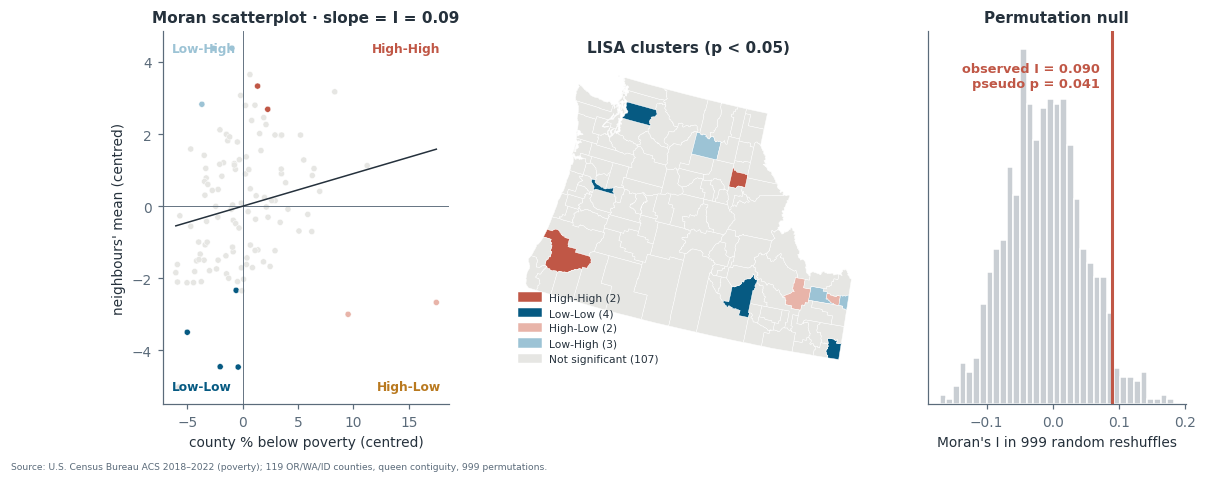

Global Moran's I = 0.090, pseudo p = 0.041, n = 118; LISA classes: {'Not significant': 107, 'Low-Low': 4, 'Low-High': 3, 'High-Low': 2, 'High-High': 2}


In [13]:
z = R.poverty_pct.values - R.poverty_pct.mean()
n = len(z)
moran_I = (z @ (W @ z)) / (z @ z)                              # S0 = n under row standardisation
perm = np.column_stack([RNG.permutation(z) for _ in range(999)])
I_null = np.einsum("ij,ij->j", perm, W @ perm) / np.einsum("ij,ij->j", perm, perm)
p_moran = (np.sum(I_null >= moran_I) + 1) / 1000

m2 = (z @ z) / n
lagz = W @ z
Ii = z * lagz / m2
kk = kdeg.astype(int)
p_loc = np.empty(n)
for idx in range(n):                                           # conditional permutation
    draw = RNG.integers(0, n - 1, size=(999, kk[idx])); draw[draw >= idx] += 1
    sim = z[idx] * z[draw].mean(axis=1) / m2
    larger = (sim >= Ii[idx]).sum()
    p_loc[idx] = (min(larger, 999 - larger) + 1) / 1000
quad = np.select([(z > 0) & (lagz > 0), (z < 0) & (lagz < 0), (z > 0) & (lagz < 0), (z < 0) & (lagz > 0)],
                 ["High-High", "Low-Low", "High-Low", "Low-High"], default="")
R["lisa"] = np.where(p_loc < 0.05, quad, "Not significant")
LISA_COL = {"High-High": PAL["terra"], "Low-Low": PAL["blue"], "High-Low": "#E8B4A9", "Low-High": "#9CC3D5", "Not significant": "#E6E6E3"}
cnt = R.lisa.value_counts()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.25, 0.9]})
axes[0].scatter(z, lagz, s=16, c=[LISA_COL[v] for v in R.lisa], edgecolor="white", lw=0.3)
axes[0].axhline(0, color=PAL["muted"], lw=0.6); axes[0].axvline(0, color=PAL["muted"], lw=0.6)
xs = np.array([z.min(), z.max()]); axes[0].plot(xs, moran_I * xs, color=PAL["ink"], lw=1)
for (qx, qy, t) in [(0.97, 0.97, "High-High"), (0.03, 0.03, "Low-Low"), (0.97, 0.03, "High-Low"), (0.03, 0.97, "Low-High")]:
    axes[0].text(qx, qy, t, transform=axes[0].transAxes, ha="right" if qx > 0.5 else "left", va="top" if qy > 0.5 else "bottom",
                 fontsize=8, color=LISA_COL[t] if t != "High-Low" else PAL["amber"], fontweight="bold")
axes[0].set_xlabel("county % below poverty (centred)"); axes[0].set_ylabel("neighbours' mean (centred)")
axes[0].set_title(f"Moran scatterplot · slope = I = {moran_I:.2f}")
R.plot(ax=axes[1], color=R.lisa.map(LISA_COL), edgecolor="white", lw=0.3)
axes[1].legend([Patch(color=c) for c in LISA_COL.values()], [f"{k} ({cnt.get(k, 0)})" for k in LISA_COL],
               loc="lower left", fontsize=7)
axes[1].set_title("LISA clusters (p < 0.05)"); axes[1].set_axis_off()
axes[2].hist(I_null, bins=35, color="#C9CED3", edgecolor="white")
axes[2].axvline(moran_I, color=PAL["terra"], lw=2)
axes[2].annotate(f"observed I = {moran_I:.3f}\npseudo p = {p_moran:.3f}", (moran_I, axes[2].get_ylim()[1] * 0.85),
                 xytext=(-8, 0), textcoords="offset points", ha="right", color=PAL["terra"], fontsize=8.5, fontweight="bold")
axes[2].set_yticks([]); axes[2].set_xlabel("Moran's I in 999 random reshuffles"); axes[2].set_title("Permutation null")
source(fig, "U.S. Census Bureau ACS 2018–2022 (poverty); 119 OR/WA/ID counties, queen contiguity, 999 permutations.")
save(fig, "clusters_moran_lisa.png", 27)
print(f"Global Moran's I = {moran_I:.3f}, pseudo p = {p_moran:.3f}, n = {n}; LISA classes: {cnt.to_dict()}")

### 4.2 Correlation between two variables (slides 28–30)
Figure 7 asks whether **one** variable resembles itself across space (autocorrelation). Slides 28–30 ask whether **two** co-located variables move together. Here: forest share and elevation on a ~5 km grid over the focus area.

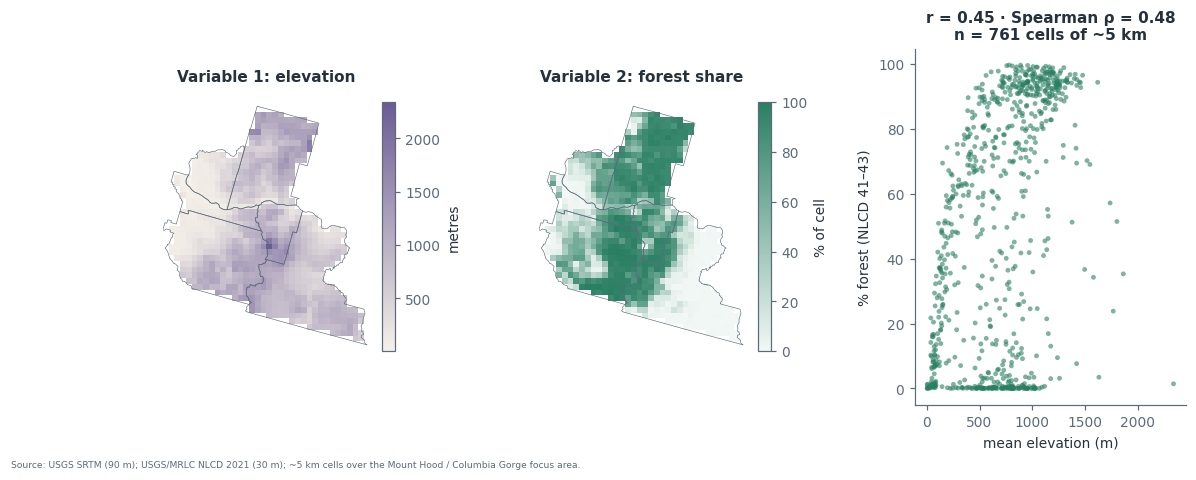

In [14]:
with rasterio.open(RAS8 / "focus_srtm_90m.tif") as src:
    dem, dem_tf = src.read(1, masked=True), src.transform
CELL = 4950.0                                                  # 165 NLCD cells = 55 SRTM cells
gx0, gy1 = lc_tf.c, lc_tf.f


def block_stats(values, valid, tf):
    rows, cols = np.nonzero(valid)
    xs, ys = rasterio.transform.xy(tf, rows, cols)
    gi = ((gy1 - np.asarray(ys)) // CELL).astype(int); gj = ((np.asarray(xs) - gx0) // CELL).astype(int)
    shape = (gi.max() + 1, gj.max() + 1)
    s = np.zeros(shape); c = np.zeros(shape)
    np.add.at(s, (gi, gj), values[rows, cols]); np.add.at(c, (gi, gj), 1)
    return s, c


fs, fc = block_stats(np.isin(lc, FOREST_CODES).astype(float), land, lc_tf)
es, ec = block_stats(dem.filled(0).astype(float), ~dem.mask, dem_tf)
H, Wd = min(fs.shape[0], es.shape[0]), min(fs.shape[1], es.shape[1])
full = fc[:H, :Wd] >= 0.8 * (CELL / 30) ** 2                   # cells at least 80 % inside the focus area
forest_pct = np.where(full, 100 * fs[:H, :Wd] / np.maximum(fc[:H, :Wd], 1), np.nan)
elev = np.where(full, es[:H, :Wd] / np.maximum(ec[:H, :Wd], 1), np.nan)
okc = np.isfinite(forest_pct) & np.isfinite(elev)
r_p, _ = stats.pearsonr(elev[okc], forest_pct[okc]); r_s, _ = stats.spearmanr(elev[okc], forest_pct[okc])
ext = (gx0, gx0 + Wd * CELL, gy1 - H * CELL, gy1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.05], "wspace": 0.45})
im0 = axes[0].imshow(elev, extent=ext, cmap=ramp("#F5F1E8", PAL["purple"]), interpolation="nearest")
fig.colorbar(im0, ax=axes[0], shrink=0.7, label="metres"); axes[0].set_title("Variable 1: elevation")
im1 = axes[1].imshow(forest_pct, extent=ext, cmap=SEQ_GREEN, vmin=0, vmax=100, interpolation="nearest")
fig.colorbar(im1, ax=axes[1], shrink=0.7, label="% of cell"); axes[1].set_title("Variable 2: forest share")
for a in axes[:2]:
    focus.boundary.plot(ax=a, color=PAL["muted"], lw=0.4); a.set_axis_off()
axes[2].scatter(elev[okc], forest_pct[okc], s=10, color=PAL["green"], alpha=0.6, edgecolor="none")
axes[2].set_xlabel("mean elevation (m)"); axes[2].set_ylabel("% forest (NLCD 41–43)")
axes[2].set_title(f"r = {r_p:.2f} · Spearman ρ = {r_s:.2f}\nn = {okc.sum()} cells of ~5 km")
source(fig, "USGS SRTM (90 m); USGS/MRLC NLCD 2021 (30 m); ~5 km cells over the Mount Hood / Columbia Gorge focus area.")
save(fig, "spatial_correlation_two_variables.png", 28)

### 4.3 Hot and cold spots: Getis-Ord Gi* (slide 33)
Gi\* includes the county itself and asks whether the **local sum** is unusually high or low.

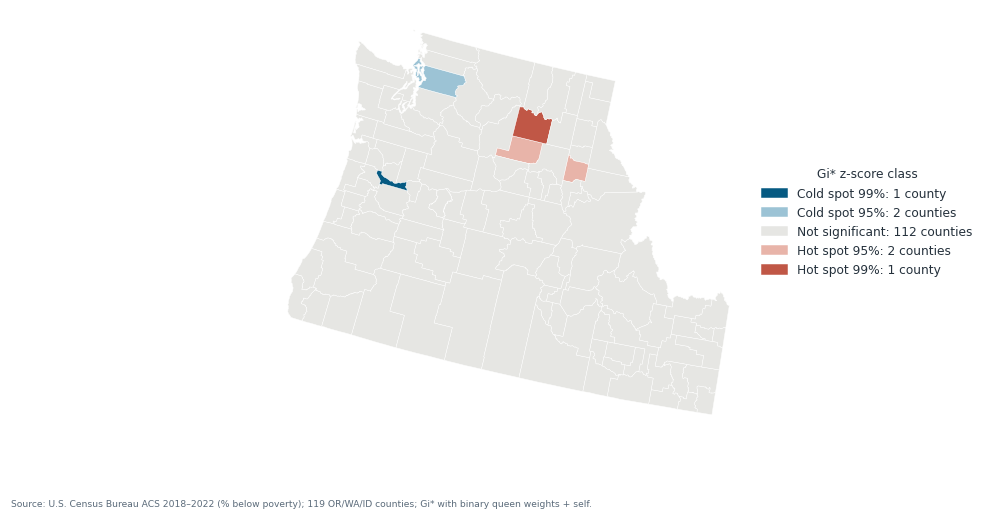

gi_class
Cold spot 99%        1
Cold spot 95%        2
Not significant    112
Hot spot 95%         2
Hot spot 99%         1
Counties both LISA High-High and Gi* hot: 1


In [15]:
Wstar = Wb + sparse.eye(n, format="csr")
xv = R.poverty_pct.values
S, Xbar = xv.std(ddof=0), xv.mean()
Wsum = np.asarray(Wstar.sum(axis=1)).ravel()
Gi = ((Wstar @ xv) - Xbar * Wsum) / (S * np.sqrt((n * np.asarray(Wstar.multiply(Wstar).sum(axis=1)).ravel() - Wsum ** 2) / (n - 1)))
GI_NAMES = ["Cold spot 99%", "Cold spot 95%", "Not significant", "Hot spot 95%", "Hot spot 99%"]
GI_COL = dict(zip(GI_NAMES, [PAL["blue"], "#9CC3D5", "#E6E6E3", "#E8B4A9", PAL["terra"]]))
R["gi_class"] = pd.cut(Gi, [-np.inf, -2.58, -1.96, 1.96, 2.58, np.inf], labels=GI_NAMES).astype(str)
gcount = R.gi_class.value_counts().reindex(GI_NAMES, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))
R.plot(ax=ax, color=R.gi_class.map(GI_COL), edgecolor="white", lw=0.3)
ax.legend([Patch(color=GI_COL[k]) for k in GI_NAMES], [f"{k}: {gcount[k]} {'county' if gcount[k] == 1 else 'counties'}" for k in GI_NAMES],
          loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, title="Gi* z-score class", title_fontsize=8)
ax.set_axis_off()
source(fig, "U.S. Census Bureau ACS 2018–2022 (% below poverty); 119 OR/WA/ID counties; Gi* with binary queen weights + self.")
save(fig, "hotspots_getis_ord.png", 33)
print(gcount.to_string())
print(f"Counties both LISA High-High and Gi* hot: {((Gi > 1.96) & (R.lisa == 'High-High')).sum()}")

### 4.4 Point patterns: clustered, random or dispersed? (slide 34)

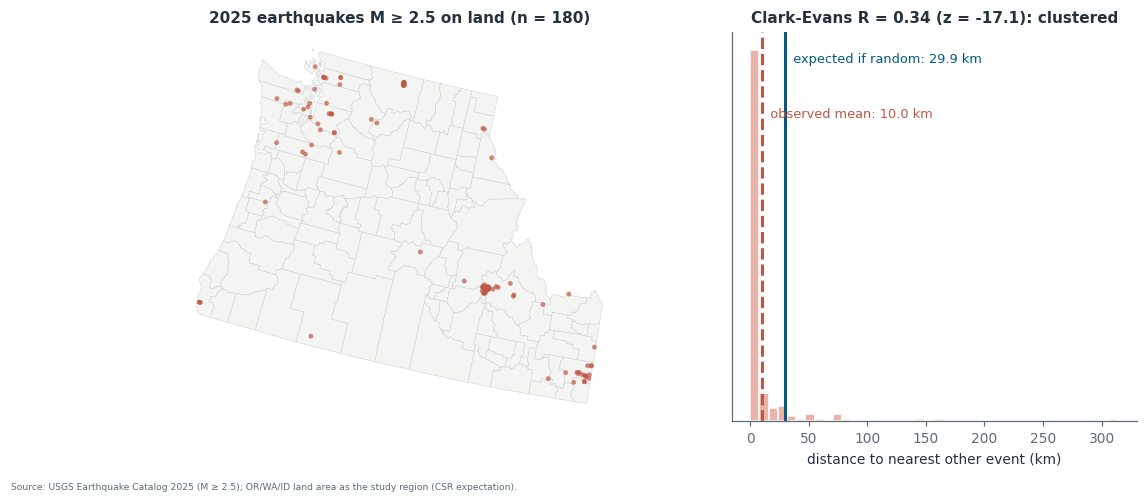

n = 180, mean NN 10.0 km vs 29.9 km under CSR, R = 0.336, z = -17.1
CANNOT ESTABLISH: why counties or events cluster. Moran's I and Gi* describe similarity among neighbours under one weights matrix; ~118 local tests at p < 0.05 without correction expect ~6 false positives; the earthquake pattern also reflects where seismometers are dense, and the CSR test depends on the chosen study area.


In [16]:
quakes = gpd.read_file(VEC / "usgs_earthquakes_2025_m25.shp").to_crs(ALBERS)
region = pnw.union_all()
q = quakes[quakes.within(region)].reset_index(drop=True)
xy = np.c_[q.geometry.x, q.geometry.y]
d_nn = cKDTree(xy).query(xy, k=2)[0][:, 1]
area_m2 = region.area
r_obs, r_exp = d_nn.mean(), 0.5 / np.sqrt(len(q) / area_m2)
ce_R = r_obs / r_exp
ce_z = (r_obs - r_exp) / (0.26136 / np.sqrt(len(q) ** 2 / area_m2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
pnw.plot(ax=a1, color="#F4F4F2", edgecolor="#C9CED3", lw=0.3)
a1.scatter(xy[:, 0], xy[:, 1], s=10, color=PAL["terra"], alpha=0.7, edgecolor="none")
a1.set_title(f"2025 earthquakes M ≥ 2.5 on land (n = {len(q)})"); a1.set_axis_off()
a2.hist(d_nn / 1000, bins=40, color="#E8B4A9", edgecolor="white")
a2.axvline(r_exp / 1000, color=PAL["blue"], lw=2)
a2.axvline(r_obs / 1000, color=PAL["terra"], lw=2, ls="--")
a2.text(r_exp / 1000, a2.get_ylim()[1] * 0.92, f"  expected if random: {r_exp / 1000:.1f} km", color=PAL["blue"], fontsize=8.5)
a2.text(r_obs / 1000, a2.get_ylim()[1] * 0.78, f"  observed mean: {r_obs / 1000:.1f} km", color=PAL["terra"], fontsize=8.5)
a2.set_xlabel("distance to nearest other event (km)"); a2.set_yticks([])
a2.set_title(f"Clark-Evans R = {ce_R:.2f} (z = {ce_z:.1f}): clustered")
source(fig, "USGS Earthquake Catalog 2025 (M ≥ 2.5); OR/WA/ID land area as the study region (CSR expectation).")
save(fig, "point_pattern_nn.png", 34)
print(f"n = {len(q)}, mean NN {r_obs / 1000:.1f} km vs {r_exp / 1000:.1f} km under CSR, R = {ce_R:.3f}, z = {ce_z:.1f}")
cannot("why counties or events cluster. Moran's I and Gi* describe similarity among neighbours under one weights "
       f"matrix; ~{n} local tests at p < 0.05 without correction expect ~{round(0.05 * n)} false positives; the "
       "earthquake pattern also reflects where seismometers are dense, and the CSR test depends on the chosen study area.")

---
## 5 · Remote Sensing and Machine Learning  (slides 36–41) · **LO 3**
GIS starts from objects; remote sensing starts from a **signal**. The pipeline below — reflectance → index → classified objects — is the poverty-from-space workflow (slide 37) in miniature, on the **Sentinel-2** scene of Champaign–Urbana from the Week 7 pack (4 bands, 10 m, summer 2023), with **NLCD 2021** as training labels.

In [17]:
with rasterio.open(RAS / "champaign_sentinel2_2023_10m.tif") as src:
    s2 = src.read().astype("float32") / 10000.0
    s2_tf, s2_crs, s2_ext = src.transform, src.crs, plotting_extent(src)
red, green, blue, nir = s2
ndvi = (nir - red) / (nir + red + 1e-9)


def stretch(bands, lo=2, hi=98):
    out = []
    for b in bands:
        p1, p2 = np.percentile(b, [lo, hi]); out.append(np.clip((b - p1) / (p2 - p1 + 1e-9), 0, 1))
    return np.dstack(out)


from rasterio.warp import reproject, Resampling
with rasterio.open(RAS / "illinois_landcover_nlcd2021_150m.tif") as src:
    labels = np.zeros(s2.shape[1:], dtype="uint8")
    reproject(rasterio.band(src, 1), labels, src_transform=src.transform, src_crs=src.crs,
              dst_transform=s2_tf, dst_crs=s2_crs, resampling=Resampling.nearest)
    CH_CMAP = {k: tuple(c / 255 for c in v) for k, v in src.colormap(1).items()}
CH_LABEL = dict(pd.read_csv(RAS / "nlcd_classes.csv").values)

X = np.stack([red, green, blue, nir, ndvi], -1).reshape(-1, 5)
yv = labels.ravel()
usable = (yv > 0) & np.isfinite(X).all(axis=1)
vc = pd.Series(yv[usable]).value_counts()
classes = sorted(vc[vc >= 2000].index)
usable &= np.isin(yv, classes)
idx = RNG.choice(np.flatnonzero(usable), size=min(120_000, usable.sum()), replace=False)
Xtr, Xte, ytr, yte = train_test_split(X[idx], yv[idx], test_size=0.3, random_state=570, stratify=yv[idx])
rf = RandomForestClassifier(n_estimators=120, min_samples_leaf=5, n_jobs=-1, random_state=570).fit(Xtr, ytr)
pred = rf.predict(Xte)
acc = accuracy_score(yte, pred)
full = rf.predict(np.nan_to_num(X)).reshape(labels.shape)
print(f"train {len(Xtr):,} / test {len(Xte):,} pixels · {len(classes)} classes · overall accuracy {acc:.3f}")

train 84,000 / test 36,000 pixels · 11 classes · overall accuracy 0.683


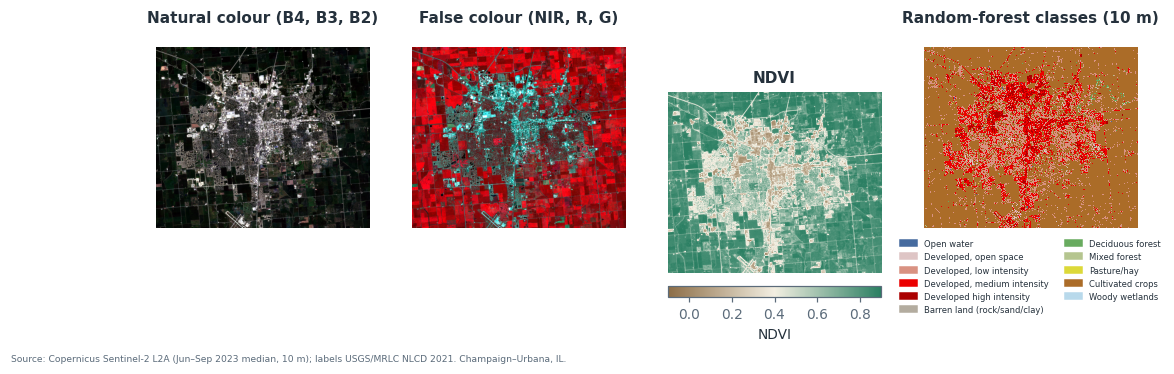

In [18]:
lut = np.ones((256, 4))
for c in classes:
    lut[c] = CH_CMAP[c]
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.9))
axes[0].imshow(stretch([red, green, blue]), extent=s2_ext); axes[0].set_title("Natural colour (B4, B3, B2)")
axes[1].imshow(stretch([nir, red, green]), extent=s2_ext); axes[1].set_title("False colour (NIR, R, G)")
im = axes[2].imshow(ndvi, extent=s2_ext, cmap=ramp("#8C6D46", "#F3EFE2", PAL["green"]), vmin=-0.1, vmax=0.9)
fig.colorbar(im, ax=axes[2], orientation="horizontal", fraction=0.05, pad=0.04, label="NDVI"); axes[2].set_title("NDVI")
axes[3].imshow(lut[full], extent=s2_ext, interpolation="nearest"); axes[3].set_title("Random-forest classes (10 m)")
axes[3].legend([Patch(color=CH_CMAP[c]) for c in classes], [CH_LABEL[c] for c in classes], fontsize=5.5, ncol=2,
               loc="upper center", bbox_to_anchor=(0.5, -0.02))
for a in axes:
    a.set_axis_off()
source(fig, "Copernicus Sentinel-2 L2A (Jun–Sep 2023 median, 10 m); labels USGS/MRLC NLCD 2021. Champaign–Urbana, IL.")
save(fig, "rs_ndvi_classification.png", 37)

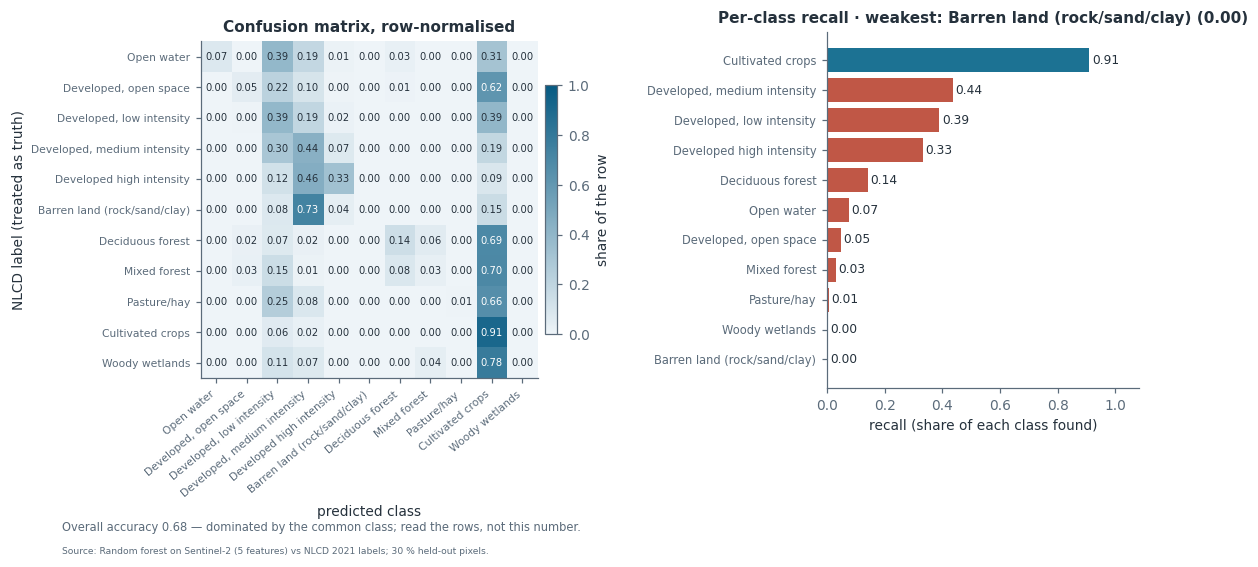

,recall,test pixels
Barren land (rock/sand/clay),0.000,26
Woody wetlands,0.000,27
Pasture/hay,0.005,558
Mixed forest,0.030,231
"Developed, open space",0.047,1224
Open water,0.075,80
Deciduous forest,0.141,198
Developed high intensity,0.331,1401
"Developed, low intensity",0.389,6013
"Developed, medium intensity",0.436,4587


CANNOT ESTABLISH: how well the model sees the ground. It reproduces another classification (NLCD at 150 m) from 10 m pixels, so some 'errors' belong to the labels; one scene and one season; accuracy depends on which classes were kept.


In [19]:
cm = confusion_matrix(yte, pred, labels=classes)
cmn = cm / cm.sum(axis=1, keepdims=True)
names = [CH_LABEL[c] for c in classes]
recall = pd.Series(cm.diagonal() / cm.sum(axis=1), index=names).sort_values()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.8})
im = a1.imshow(cmn, cmap=SEQ_BLUE, vmin=0, vmax=1)
a1.set_xticks(range(len(classes)), names, rotation=40, ha="right", fontsize=7)
a1.set_yticks(range(len(classes)), names, fontsize=7)
a1.set_xlabel("predicted class"); a1.set_ylabel("NLCD label (treated as truth)")
for r in range(len(classes)):
    for c in range(len(classes)):
        a1.text(c, r, f"{cmn[r, c]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if cmn[r, c] > 0.55 else PAL["ink"])
fig.colorbar(im, ax=a1, shrink=0.7, fraction=0.04, pad=0.02, label="share of the row")
a1.set_title("Confusion matrix, row-normalised")
cols = [PAL["terra"] if v < 0.5 else PAL["teal"] for v in recall]
a2.barh(recall.index, recall.values, color=cols)
for k, v in enumerate(recall.values):
    a2.text(v + 0.01, k, f"{v:.2f}", va="center", fontsize=8)
a2.set_xlim(0, 1.08); a2.set_xlabel("recall (share of each class found)"); a2.tick_params(axis="y", labelsize=7.5)
a2.set_title(f"Per-class recall · weakest: {recall.index[0]} ({recall.iloc[0]:.2f})")
fig.text(0.01, -0.2, f"Overall accuracy {acc:.2f} — dominated by the common class; read the rows, not this number.",
         fontsize=7.5, color=PAL["muted"])
fig.text(0.01, -0.235, "Source: Random forest on Sentinel-2 (5 features) vs NLCD 2021 labels; 30 % held-out pixels.",
         fontsize=6, color=PAL["muted"], va="top")
save(fig, "ml_confusion_matrix.png", 41)
display(pd.DataFrame({"recall": recall.round(3), "test pixels": pd.Series(cm.sum(axis=1), index=names)}).sort_values("recall"))
cannot("how well the model sees the ground. It reproduces another classification (NLCD at 150 m) from 10 m pixels, "
       "so some 'errors' belong to the labels; one scene and one season; accuracy depends on which classes were kept.")

---
## 6 · Policy and the Politics of Categories  (slides 43–46) · **LO 4**
Robbins (2001): land-cover categories are **decisions that become infrastructure**. Three demonstrations.

### 6.1 Who defines "forest" — and "protected"? (slide 43)

,km²,% of focus area
Canopy in blocks ≥ 1 km²,9232.9,46.8
"Canopy, FAO minimum 0.5 ha",9834.2,49.9
"Canopy (NLCD 41, 42, 43)",9860.5,50.0
+ woody wetlands (90),10035.0,50.9
+ shrub/scrub (52): 'other wooded land',12010.2,60.9


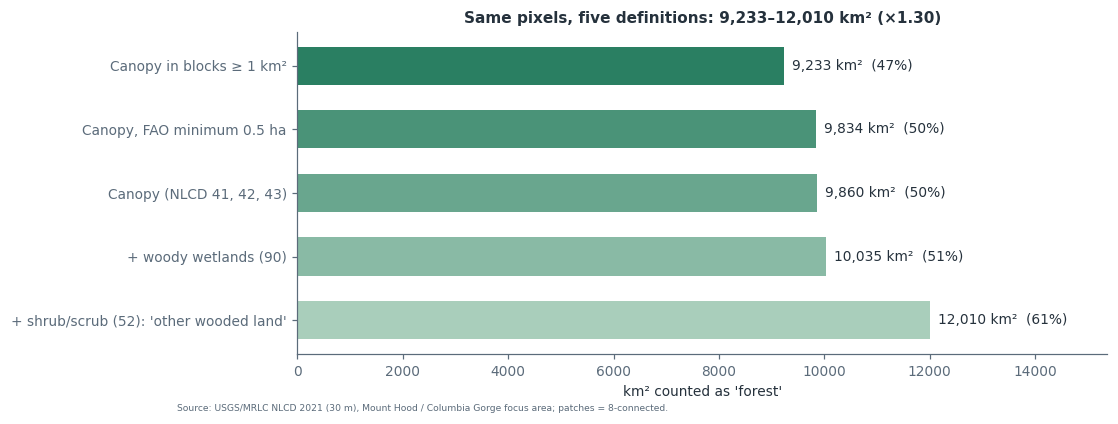

,km² (dissolved),% of focus area
definition of 'protected',,
GAP 1 only (wilderness-like),1425.3,7.2
GAP 1–2 (managed for biodiversity),2085.1,10.6
GAP 1–3 (+ multiple use),9774.3,49.5
any PAD-US record (GAP 1–4),9976.7,50.6


In [20]:
def patch_filter(mask, min_km2):
    lab, _ = ndimage.label(mask, structure=np.ones((3, 3)))
    sizes = np.bincount(lab.ravel()) * CELL_KM2; sizes[0] = 0
    return (sizes >= min_km2)[lab]


canopy = np.isin(lc, FOREST_CODES) & land
DEFS = {
    "Canopy in blocks ≥ 1 km²": patch_filter(canopy, 1.0),
    "Canopy, FAO minimum 0.5 ha": patch_filter(canopy, 0.005),
    "Canopy (NLCD 41, 42, 43)": canopy,
    "+ woody wetlands (90)": np.isin(lc, FOREST_CODES + [90]) & land,
    "+ shrub/scrub (52): 'other wooded land'": np.isin(lc, FOREST_CODES + [90, 52]) & land,
}
land_km2 = land.sum() * CELL_KM2
fd = pd.DataFrame({"km²": {k: m.sum() * CELL_KM2 for k, m in DEFS.items()}})
fd["% of focus area"] = 100 * fd["km²"] / land_km2
display(fd.round(1))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
colours = [ramp("#BFDCCB", PAL["green"])(t) for t in np.linspace(1, 0.15, len(fd))]
ax.barh(fd.index, fd["km²"], color=colours, height=0.6)
for k, (v, p) in enumerate(zip(fd["km²"], fd["% of focus area"])):
    ax.text(v + land_km2 * 0.008, k, f"{v:,.0f} km²  ({p:.0f}%)", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, fd["km²"].max() * 1.28); ax.set_xlabel("km² counted as 'forest'")
ax.set_title(f"Same pixels, five definitions: {fd['km²'].min():,.0f}–{fd['km²'].max():,.0f} km² "
             f"(×{fd['km²'].max() / fd['km²'].min():.2f})")
source(fig, "USGS/MRLC NLCD 2021 (30 m), Mount Hood / Columbia Gorge focus area; patches = 8-connected.")
save(fig, "categories_forest_definitions.png", 43)

prot = pd.DataFrame({"definition of 'protected'": ["GAP 1 only (wilderness-like)", "GAP 1–2 (managed for biodiversity)",
                                                   "GAP 1–3 (+ multiple use)", "any PAD-US record (GAP 1–4)"],
                     "km² (dissolved)": [pad[pad.GAP <= g].union_all().area / 1e6 for g in (1, 2, 3, 4)]})
prot["% of focus area"] = 100 * prot["km² (dissolved)"] / (focus.area.sum() / 1e6)
display(prot.round(1).set_index("definition of 'protected'"))

### 6.2 MAUP: the same events, two aggregations (slide 45)

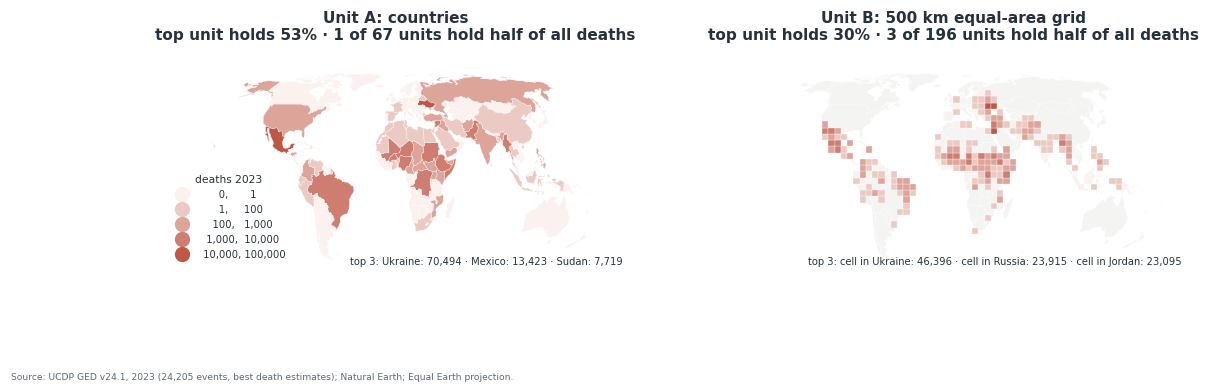

countries: top 53.3%, 1 units hold half | 500 km cells: top 30.0%, 3 units hold half


In [21]:
ged = pd.read_csv(TAB / "ucdp_ged_events_2023.csv")
ged_pts = gpd.GeoDataFrame(ged, geometry=gpd.points_from_xy(ged.longitude, ged.latitude), crs=4326)
wmap = world[world.CONTINENT != "Antarctica"].to_crs(8857)
gp = ged_pts.to_crs(8857)
by_country = gpd.sjoin(gp, wmap[["NAME", "geometry"]], predicate="within", how="inner").groupby("NAME").deaths_best.sum()
GRID = 500_000
gx, gy = np.floor(gp.geometry.x / GRID).astype(int), np.floor(gp.geometry.y / GRID).astype(int)
by_cell = gp.assign(gx=gx, gy=gy).groupby(["gx", "gy"]).deaths_best.sum()
cells = gpd.GeoDataFrame({"deaths": by_cell.values},
                         geometry=[box(a * GRID, b * GRID, (a + 1) * GRID, (b + 1) * GRID) for a, b in by_cell.index], crs=8857)


def concentration(s):
    s = s.sort_values(ascending=False)
    return 100 * s.iloc[0] / s.sum(), int((s.cumsum() / s.sum() < 0.5).sum() + 1), len(s)


cc, cg = concentration(by_country), concentration(by_cell)
top_c = by_country.sort_values(ascending=False).head(3)
cells_rank = cells.sort_values("deaths", ascending=False).head(3)
cells_rank_names = [gpd.sjoin(gpd.GeoDataFrame(geometry=[g.centroid], crs=8857), wmap[["NAME", "geometry"]],
                              predicate="within", how="left").NAME.iloc[0] for g in cells_rank.geometry]
bins = [1, 100, 1000, 10000, 100000]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
wmap.plot(ax=axes[0], column=wmap.NAME.map(by_country).fillna(0), cmap=SEQ_TERRA, scheme="UserDefined",
          classification_kwds={"bins": bins}, edgecolor="white", lw=0.2, legend=True,
          legend_kwds={"fmt": "{:,.0f}", "loc": "lower left", "fontsize": 6.5, "title": "deaths 2023", "title_fontsize": 7})
wmap.plot(ax=axes[1], color="#F4F4F2", edgecolor="white", lw=0.2)
cells.plot(ax=axes[1], column="deaths", cmap=SEQ_TERRA, scheme="UserDefined", classification_kwds={"bins": bins},
           edgecolor="white", lw=0.2)
for ax, (share, k50, nu), ttl, tops in [
        (axes[0], cc, "Unit A: countries", [f"{n_}: {v:,.0f}" for n_, v in top_c.items()]),
        (axes[1], cg, "Unit B: 500 km equal-area grid", [f"cell in {n_}: {v:,.0f}" for n_, v in zip(cells_rank_names, cells_rank.deaths)])]:
    ax.set_title(f"{ttl}\ntop unit holds {share:.0f}% · {k50} of {nu} units hold half of all deaths")
    ax.text(0.99, 0.02, "top 3: " + " · ".join(tops), transform=ax.transAxes, ha="right", fontsize=6.5, color=PAL["ink"])
    ax.set_axis_off()
source(fig, "UCDP GED v24.1, 2023 (24,205 events, best death estimates); Natural Earth; Equal Earth projection.")
save(fig, "maup_two_aggregations.png", 45)
print(f"countries: top {cc[0]:.1f}%, {cc[1]} units hold half | 500 km cells: top {cg[0]:.1f}%, {cg[1]} units hold half")

### 6.3 Ethics: exact points vs an aggregated rate (slide 46)

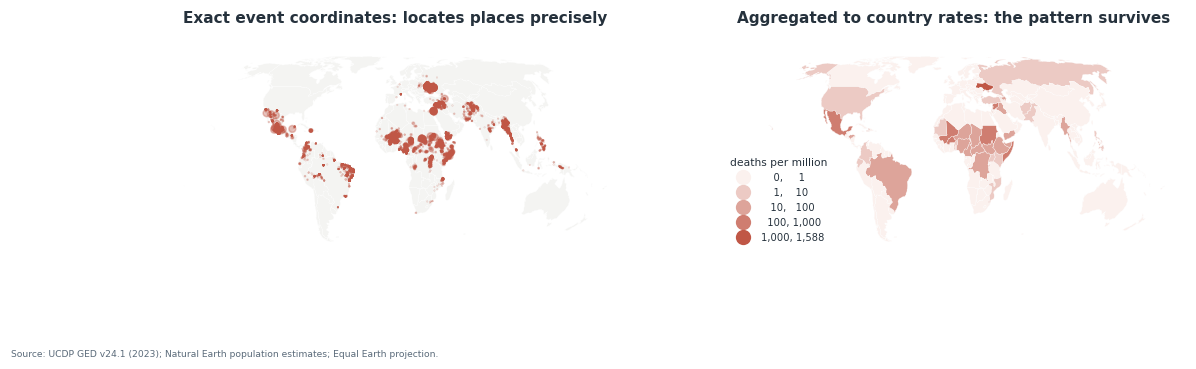

CANNOT ESTABLISH: which aggregation is 'correct' — the MAUP has no neutral unit — or that the aggregated map is harmless; small countries can still be re-identified. The forest and protected areas above change by definition alone, so any target or subsidy built on them inherits that choice.


In [22]:
wc = wmap.copy()
wc["deaths"] = wc.NAME.map(by_country).fillna(0)
wc["per_million"] = wc.deaths / wc.POP_EST.replace(0, np.nan) * 1e6
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
wmap.plot(ax=axes[0], color="#F4F4F2", edgecolor="white", lw=0.2)
gp.plot(ax=axes[0], markersize=np.clip(ged.deaths_best, 1, 300) / 15, color=PAL["terra"], alpha=0.35)
axes[0].set_title("Exact event coordinates: locates places precisely")
wc.plot(ax=axes[1], column="per_million", cmap=SEQ_TERRA, scheme="UserDefined", classification_kwds={"bins": [1, 10, 100, 1000, float(wc.per_million.max())]},
        edgecolor="white", lw=0.2, legend=True, missing_kwds=MISSING,
        legend_kwds={"fmt": "{:,.0f}", "loc": "lower left", "fontsize": 6.5, "title": "deaths per million", "title_fontsize": 7})
axes[1].set_title("Aggregated to country rates: the pattern survives")
for a in axes:
    a.set_axis_off()
source(fig, "UCDP GED v24.1 (2023); Natural Earth population estimates; Equal Earth projection.")
save(fig, "ethics_point_vs_aggregated.png", 46)
cannot("which aggregation is 'correct' — the MAUP has no neutral unit — or that the aggregated map is harmless; "
       "small countries can still be re-identified. The forest and protected areas above change by definition alone, "
       "so any target or subsidy built on them inherits that choice.")

---
## 7 · Discussion and AI Engagement  (slides 48–49)
**Who defines the categories?** Use §6.1: the focus area has between the smallest and the largest forest figure without a pixel changing, and strict protection covers a fraction of what "any PAD-US record" suggests. If a plot is "degraded forest" rather than "pastoral commons", who gains and who loses?

**AI task.** Prompt an AI for an **analysis** (not a map) with the brief below, then compare it with your own on three points: did it justify the buffer distance, state the unit and the MAUP risk, and name a limit?

In [23]:
BRIEF = '''
Propose a spatial analysis for [policy question], using [layers], at [unit of analysis].
OPERATION — overlay (which of clip/intersect/erase/union/identity), buffer, proximity or cluster detection; what each assumes.
  If a buffer: give the distance AND justify it; show the result at two other distances.
  If clustering: name the statistic, the weights and the null model.
DATA AND UNITS — CRS (equal-area for areas, metres for distances; EPSG code); unit of analysis and its MAUP risk;
  counts, per-capita rates or per-km² densities, and why.
OUTPUT AND LIMITS — one sentence of interpretation and one sentence on what the analysis CANNOT establish;
  whether the output locates vulnerable people precisely (if so, aggregate first).
DO NOT — report a p-value without the null model, an accuracy without per-class results, or invent a layer.
'''
print(BRIEF)


Propose a spatial analysis for [policy question], using [layers], at [unit of analysis].
OPERATION — overlay (which of clip/intersect/erase/union/identity), buffer, proximity or cluster detection; what each assumes.
  If a buffer: give the distance AND justify it; show the result at two other distances.
  If clustering: name the statistic, the weights and the null model.
DATA AND UNITS — CRS (equal-area for areas, metres for distances; EPSG code); unit of analysis and its MAUP risk;
  counts, per-capita rates or per-km² densities, and why.
OUTPUT AND LIMITS — one sentence of interpretation and one sentence on what the analysis CANNOT establish;
  whether the output locates vulnerable people precisely (if so, aggregate first).
DO NOT — report a p-value without the null model, an accuracy without per-class results, or invent a layer.



---
## 8 · Lab and Deliverable  (slides 51–52) · **LO 5**
| Time | Step (slide 51) | QGIS |
|---|---|---|
| 0–15′ | Overlay: forest × protected areas; measure the gap | `focus_nlcd2021_30m.tif` → *Raster ▸ Conversion ▸ Polygonize* (or reclassify), `padus41_mthood_gorge.shp` filtered `"GAP_Sts" <= '2'` → *Vector ▸ Geoprocessing ▸ Intersection / Difference* |
| 15–30′ | Buffer around conflict events; which camps fall inside? | `ucdp_ged_2023_near_camps.csv` (*Add Delimited Text Layer*, EPSG:4326) → reproject to EPSG:32646 → *Buffer* at two distances → *Select by Location* on `coxsbazar_camps_2023.shp` |
| 30–40′ | Pick one: a spatial statistic · Earth Engine task · OSINT overlay | GeoDa on `us_counties_acs2022.shp` (Moran/LISA); or `ucdp_ged_events_2023.csv` aggregated by country |
| 40–55′ | Export maps; write the memo | *Project ▸ New Print Layout* |

**Deliverable (slide 52):** exported map(s) + a 200–300-word memo with **one policy implication**; optional OSINT and AI reflections.

In [24]:
memo = f'''# Week 8 workflow memo

## Question
[One sentence: what policy question does this analysis answer?]

## Data and units
- Focus area: {", ".join(sorted(focus.NAME))} ({len(focus)} counties), EPSG:{ALBERS} (equal-area, metres)
- Forest: NLCD 2021, 30 m, classes {FOREST_CODES}. Five other defensible definitions give {fd["km²"].min():,.0f}–{fd["km²"].max():,.0f} km² (§6.1).
- Protected areas: PAD-US 4.1, GAP status 1–2 = "protected" here; GAP 1–3 would change the answer (§2.4).

## Operations and results
1. Overlay: {pct12:.1f}% of forest is inside GAP 1–2 ({P12:,.0f} of {F_km2:,.0f} km²); {pct123:.1f}% inside GAP 1–3.
2. Buffer: {min(share1):.0f}%–{max(share1):.0f}% of the 33 Cox's Bazar camps are "near conflict" for radii {RADII[0]}–{RADII[-1]} km.
3. Clustering: Moran's I = {moran_I:.3f} (pseudo p = {p_moran:.3f}, queen weights, 999 permutations, {n} PNW counties).
4. Classification: overall accuracy {acc:.2f}; weakest class {recall.index[0]} (recall {recall.iloc[0]:.2f}).

## One policy implication
[What should change, for whom, on the strength of this?]

## What this analysis cannot establish
[Correlation vs mechanism; designation vs outcome; Euclidean vs travel distance; MAUP; label quality.]

## AI engagement / Ethics
[What did the AI propose, and what did it fill in silently? Does any output locate vulnerable people precisely?]
'''
(OUT / "week8_workflow_memo.md").write_text(memo)
print(memo)

gpkg = OUT / "week8_outputs.gpkg"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, g in [("forest_protected_gap12", inside12), ("forest_gap", gap_forest), ("padus_dissolved_by_gap", diss),
                    ("camps_distance_to_conflict", camps), ("pnw_counties_clusters", R.assign(gi_z=Gi, local_I=Ii, p_local=p_loc)[
                        ["geoid", "county_label", "state_abbr", "poverty_pct", "lisa", "gi_class", "gi_z", "local_I", "p_local", "geometry"]])]:
        g.to_file(gpkg, layer=name, driver="GPKG")
print("QGIS layers written to", gpkg)

# Week 8 workflow memo

## Question
[One sentence: what policy question does this analysis answer?]

## Data and units
- Focus area: Clackamas, Clark, Hood River, Multnomah, Skamania, Wasco (6 counties), EPSG:5070 (equal-area, metres)
- Forest: NLCD 2021, 30 m, classes [41, 42, 43]. Five other defensible definitions give 9,233–12,010 km² (§6.1).
- Protected areas: PAD-US 4.1, GAP status 1–2 = "protected" here; GAP 1–3 would change the answer (§2.4).

## Operations and results
1. Overlay: 14.0% of forest is inside GAP 1–2 (1,377 of 9,860 km²); 73.3% inside GAP 1–3.
2. Buffer: 64%–100% of the 33 Cox's Bazar camps are "near conflict" for radii 1–100 km.
3. Clustering: Moran's I = 0.090 (pseudo p = 0.041, queen weights, 999 permutations, 118 PNW counties).
4. Classification: overall accuracy 0.68; weakest class Barren land (rock/sand/clay) (recall 0.00).

## One policy implication
[What should change, for whom, on the strength of this?]

## What this analysis cannot establish
[Correlation 

QGIS layers written to outputs/week8_outputs.gpkg


### Figure checklist and headline numbers

In [25]:
EXPECTED = {"overlay_operations.png": 17, "overlay_policy_forest_protected.png": 18, "distance_to_water_development.png": 21,
            "buffer_sensitivity.png": 23, "proximity_toolbox.png": 24, "data_preprocessing_dissolve_integrate.png": 25,
            "clusters_moran_lisa.png": 27, "spatial_correlation_two_variables.png": 28, "hotspots_getis_ord.png": 33,
            "point_pattern_nn.png": 34, "rs_ndvi_classification.png": 37, "ml_confusion_matrix.png": 41,
            "categories_forest_definitions.png": 43, "maup_two_aggregations.png": 45, "ethics_point_vs_aggregated.png": 46}
table = pd.DataFrame([{"figure": f, "deck slide": s, "written": (OUT / f).exists(),
                       "kB": round((OUT / f).stat().st_size / 1024) if (OUT / f).exists() else None} for f, s in EXPECTED.items()])
display(table.set_index("figure"))
assert table.written.all() and set(FIGS) == set(EXPECTED), "missing figures: " + str(set(EXPECTED) - set(FIGS))
print(f"All {len(EXPECTED)} figures written.\n")
print("Headline numbers for the lecture:")
print(f"  forest strictly protected (GAP 1-2): {pct12:.1f}%  |  incl. multiple use (GAP 1-3): {pct123:.1f}%")
print(f"  buffer sensitivity: {min(share1):.0f}% -> {max(share1):.0f}% of camps 'near conflict' for {RADII[0]}-{RADII[-1]} km")
print(f"  Moran's I = {moran_I:.3f}, pseudo p = {p_moran:.3f} ({n} PNW counties)")
print(f"  classifier accuracy {acc:.2f}; weakest class: {recall.index[0]} (recall {recall.iloc[0]:.2f})")
print(f"  forest definitions: {fd['km²'].min():,.0f}-{fd['km²'].max():,.0f} km² (x{fd['km²'].max() / fd['km²'].min():.2f})")

,deck slide,written,kB
figure,,,
overlay_operations.png,17,True,147
overlay_policy_forest_protected.png,18,True,543
distance_to_water_development.png,21,True,522
buffer_sensitivity.png,23,True,205
proximity_toolbox.png,24,True,181
data_preprocessing_dissolve_integrate.png,25,True,518
clusters_moran_lisa.png,27,True,246
spatial_correlation_two_variables.png,28,True,281
hotspots_getis_ord.png,33,True,193


All 15 figures written.

Headline numbers for the lecture:
  forest strictly protected (GAP 1-2): 14.0%  |  incl. multiple use (GAP 1-3): 73.3%
  buffer sensitivity: 64% -> 100% of camps 'near conflict' for 1-100 km
  Moran's I = 0.090, pseudo p = 0.041 (118 PNW counties)
  classifier accuracy 0.68; weakest class: Barren land (rock/sand/clay) (recall 0.00)
  forest definitions: 9,233-12,010 km² (x1.30)
